# Predicting Household Escape from Poverty in India (IHDS-I 2004-05 to IHDS-II 2011-12)

**Question.** Some Indian households were *poor in 2004-05*. Which of them were *no longer poor in 2011-12*, and which starting conditions (education, work, assets, health, family structure, services) go together with escaping?

**SDGs:** SDG 1 (No Poverty) and SDG 10 (Reduced Inequalities). Caste, religion, gender and state are used as inputs so that inequality can be examined directly.

**What this notebook does.** It loads the two survey rounds, links the households, measures poverty with the **same (Tendulkar) poverty line in both rounds**, builds the features, trains and tests four models on villages they have never seen, explains the best model, and checks how stable the results are. The cross-validation folds are built by our own deterministic function, so the results do not depend on the scikit-learn version.

**Application domain.** Social welfare and poverty targeting (public policy). **Task.** Binary classification (escaped or stayed poor) on panel survey data. **Users.** Welfare departments, NGOs and policy researchers.

**Registered idea and what was delivered.** The registered idea was to predict, with Logistic Regression, Random Forest and XGBoost, which households that were poor in wave 1 had crossed the poverty line by wave 2, to rank the factors with SHAP, and optionally to add a small propensity-score analysis. All of this is delivered. Refinements: one poverty line in both rounds, validation by village, an ensemble model, checks of the predicted probabilities and a demo app.

**How to use this notebook**
- Run the cells from top to bottom. Random steps use fixed seeds, and the cross-validation folds are saved, so the numbers repeat.
- Put the two ICPSR folders next to the notebook (or set the environment variable `IHDS_DATA_DIR`). Install the packages in `requirements.txt` (pinned versions).
- Tables and charts are saved in the folder `outputs/`.
- Each code line that does real work has a short comment above it. Every function has a short description (docstring) that says what goes in and what comes out.

| Section | What it does | Marks component |
|---|---|---|
| 1 | Find the data files and check they are not damaged | Dataset |
| 2 | Choose the input variables (features) before loading the data | Dataset / Features |
| 3 | Load and clean the data, **link the two survey waves**, **harmonise the poverty line**, create the target, check drop-out (attrition) | Dataset / Problem |
| 4 | Build household features, apply missing-value rules, save a feature dictionary | Dataset / Features |
| 5 | Exploratory charts | Dataset |
| 6 | Split the data into train and test (by village) | Methodology |
| 7 | Train and tune the models, then check how many features are needed (feature selection) | Methodology / Implementation |
| 8 | Test results of every model (accuracy, precision, recall, F1, confusion matrix, ROC-AUC), confidence intervals, calibration, practical lift | Results |
| 9 | Explain the model (SHAP, odds ratios) | Results / Interpretation |
| 10 | Robustness checks (a-f) | Results / Viva |
| 11 | Is education linked to escape? Valid estimators for association | Extension |
| 12 | Save everything | Reproducibility |


### Project structure and workflow

```
AUCML project folder
|-- IHDS_poverty_escape_v3.ipynb    this notebook (run it from top to bottom)
|-- ihds_tools.py                   a small helper class, also needed by the demo app
|-- requirements.txt                the exact package versions
|-- quick_check.py                  re-checks the saved results in a few seconds
|-- app.py, app_labels.json         the Streamlit demo
|-- make_charts_v3.py, build_deck_v4.py, deck_helpers.py   rebuild the charts and the slides
|-- outputs/                        tables (csv), key_numbers.json, charts, saved models
|-- ICPSR_22626-V12/, ICPSR_36151-V6/   the raw survey data (not shared outside the team)
```

**Workflow:** raw survey files -> check and clean -> link the two rounds -> measure poverty the same way in both rounds -> create the target ->
build features -> split by village -> train and tune four models -> test on unseen villages -> explain with SHAP -> save `outputs/` ->
charts, slides, report and the demo app all read from `outputs/`.

**How to read this notebook.** Sections 1 to 9 are the core project (data, features, models, results, explanation).
Sections 10 and 11 are extra checks (robustness and the education analysis). You can skip them on a first reading.


### Short glossary (plain English)
- **Wave 1 / Wave 2:** the first survey (2004-05) and the follow-up survey of the same households (2011-12).
- **Poor:** a household is poor when its monthly spending per person is below the Tendulkar poverty line (a different line for each state and for rural/urban areas). In wave 2 we use the survey's own flag `POOR`; in wave 1 we recompute the flag with the Tendulkar 2004-05 line `POVLINE2005` that ships inside the wave-2 file (the wave-1 file's own flag uses an older line).
- **Target (`ESCAPED`):** 1 if a household was poor in wave 1 but not poor in wave 2, otherwise 0.
- **Brier score / calibration:** the Brier score is the average squared error of the predicted probabilities (lower is better). A model is *calibrated* when 70% predicted probability really means about 70% of such households escaped.
- **PSU:** the village (rural) or neighbourhood (urban) where households were sampled. Households in one PSU are alike, so we never split a PSU between train and test.
- **Train / test:** the model learns from the train part and is judged on the test part it has never seen.
- **Cross-validation (CV):** repeatedly hide a part of the training data to check the model while we tune it.
- **ROC-AUC:** a score from 0.5 (guessing) to 1.0 (perfect) that tells how well the model ranks escapers above non-escapers.
- **SHAP:** a method that shows how much each input pushed a prediction up or down.
- **Leakage:** using information that would not be known at prediction time, or that is a direct copy of the answer. It makes results look better than they really are.

In [1]:
# Check that the required packages are installed (install them with: pip install -r requirements.txt).
import importlib

for package in ["numpy", "pandas", "scipy", "sklearn", "xgboost", "shap", "pyreadstat", "matplotlib"]:
    module = importlib.import_module(package)
    print(f"{package:12s} {module.__version__}")


numpy        2.0.2


pandas       2.2.3
scipy        1.14.1


sklearn      1.5.2


xgboost      2.1.3


C:\aucml\venv2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shap         0.46.0
pyreadstat   1.2.8
matplotlib   3.9.2


In [2]:
# ---- Standard Python tools ----
import hashlib
import json
import re
import time
import warnings
from pathlib import Path

# ---- Data and plotting tools ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyreadstat          # reads the Stata (.dta) survey files
import shap                # explains model predictions
from IPython.display import display

# ---- Machine-learning tools (scikit-learn and XGBoost) ----
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             matthews_corrcoef, precision_score, PrecisionRecallDisplay, recall_score,
                             roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import (cross_val_predict, cross_val_score, GroupKFold, GroupShuffleSplit,
                                     RandomizedSearchCV, StratifiedGroupKFold)
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Hide warning messages to keep the output readable.
warnings.filterwarnings("ignore")

In [3]:
# Fix the random seed so every run gives the same numbers.
SEED = 42
np.random.seed(SEED)

# Folders where tables (CSV) and charts (PNG) are saved.
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Clean chart style.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

# A dictionary that collects the key numbers for the report. It is saved at the end.
REPORT_NUMBERS = {}


def save_figure(file_name):
    """Save the current chart as a PNG file inside the figures folder.

    Input : file_name - name of the picture file, for example "eda_overview.png".
    Output: nothing (the file is written to outputs/figures/).
    """
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / file_name, dpi=200, bbox_inches="tight")

## 1. Data files and integrity check

Three ICPSR `.dta` files feed the models. A fourth (the village file) is used only in one robustness check, and a fifth (the official tracking sheet) only to cross-check our household link. The other datasets in the two ICPSR folders (medical, school, birth history, tracking, wages) are **not** needed.

| Role | ICPSR study | File | Rows | Why we need it |
|---|---|---|---|---|
| Wave 1 households (inputs + 2005 poverty flag) | 22626 (IHDS-I, 2004-05) | `DS0002/22626-0002-Data.dta` | 41,554 | one row per household, 945 variables |
| Wave 1 persons (head, education, work, health) | 22626 | `DS0001/22626-0001-Data.dta` | 215,754 | one row per person; we summarise it per household |
| Wave 2 households (outcome: poor in 2011-12?) | 36151 (IHDS-II, 2011-12) | `DS0002/36151-0002-Data.dta` | 42,152 | the same households interviewed again |
| Wave 1 villages (robustness check only) | 22626 | `DS0007/22626-0007-Data.dta` | 1,501 | roads, schools, clinics of rural villages |
| Tracking sheet (link cross-check only) | 36151 | `DS0011/36151-0011-Data.dta` | 215,754 | one row per 2005 person: where the household went in 2011-12 |

Each file is checked against the **size and MD5 checksum written in the ICPSR manifest**. A half-uploaded file (which causes the error `buffer is smaller than requested size`) is caught here with a clear message.

In [4]:
# Expected size (bytes) and MD5 checksum of each data file, copied from the ICPSR manifest files.
EXPECTED_FILES = {
    "22626-0002-Data.dta": (106257737, "df12a5cab6bd2b3b73648328afa30c90"),   # IHDS-I households
    "22626-0001-Data.dta": (120695830, "3088666d2392401a425c2aa6e51a8e99"),   # IHDS-I persons
    "36151-0002-Data.dta": (115288720, "480fe797c2cb8f04f825eaf883dc69aa"),   # IHDS-II households
    "22626-0007-Data.dta": (1532343,   "d6afc66f9a3e29327f625ea3c6c3b89d"),   # IHDS-I villages (robustness only)
    "36151-0011-Data.dta": (33675496,  "8d69c36e04ea6936af1cf9ac975c61a4"),   # IHDS-II tracking sheet (link check only)
}

# Set to False to skip the checksum test (it takes a few seconds).
CHECK_MD5 = True

# Folders searched for the data files (works on a laptop and on Google Colab).
import os
SEARCH_FOLDERS = [Path.cwd(), Path.cwd().parent, Path("/content"), Path("/content/drive/MyDrive")]
if os.environ.get("IHDS_DATA_DIR"):
    SEARCH_FOLDERS.insert(0, Path(os.environ["IHDS_DATA_DIR"]))


def find_file(file_name):
    """Look for a data file in the usual folders and return its full path.

    Input : file_name - for example "22626-0002-Data.dta".
    Output: the path of the first matching file.
    Raises: FileNotFoundError if the file is not in any search folder.
    """
    for folder in SEARCH_FOLDERS:
        if folder.exists():
            matches = list(folder.rglob(file_name))
            if matches:
                return matches[0]
    raise FileNotFoundError(f"{file_name} not found in {[str(f) for f in SEARCH_FOLDERS]}. "
                            "Put the ICPSR folders next to this notebook.")


def md5_checksum(path, chunk_size=1 << 22):
    """Compute the MD5 'fingerprint' of a file (read in blocks to save memory).

    Input : path - the file to read; chunk_size - how many bytes to read at a time.
    Output: the checksum as a text string. Two identical files give the same string.
    """
    checksum = hashlib.md5()
    with open(path, "rb") as file:
        while True:
            block = file.read(chunk_size)
            if not block:
                break
            checksum.update(block)
    return checksum.hexdigest()


# Find every file and check that it is complete and not damaged.
DATA_PATHS = {}
for file_name, (expected_size, expected_md5) in EXPECTED_FILES.items():
    path = find_file(file_name)
    size_ok = path.stat().st_size == expected_size
    md5_ok = (not CHECK_MD5) or (size_ok and md5_checksum(path) == expected_md5)
    status = "OK " if (size_ok and md5_ok) else "BAD"
    print(f"{status}  {file_name:24s} {path.stat().st_size:>12,} bytes   {path}")
    assert size_ok and md5_ok, (f"{file_name} is incomplete or damaged (expected {expected_size:,} bytes). "
                                "Copy it again; on Colab mount Google Drive instead of using the upload panel.")
    DATA_PATHS[file_name] = path

OK   22626-0002-Data.dta       106,257,737 bytes   C:\aucml\ro\ICPSR_22626-V12\ICPSR_22626\DS0002\22626-0002-Data.dta


OK   22626-0001-Data.dta       120,695,830 bytes   C:\aucml\ro\ICPSR_22626-V12\ICPSR_22626\DS0001\22626-0001-Data.dta


OK   36151-0002-Data.dta       115,288,720 bytes   C:\aucml\ro\ICPSR_36151-V6\ICPSR_36151\DS0002\36151-0002-Data.dta
OK   22626-0007-Data.dta         1,532,343 bytes   C:\aucml\ro\ICPSR_22626-V12\ICPSR_22626\DS0007\22626-0007-Data.dta
OK   36151-0011-Data.dta        33,675,496 bytes   C:\aucml\ro\ICPSR_36151-V6\ICPSR_36151\DS0011\36151-0011-Data.dta


## 2. Choosing the input variables (features) before loading

The wave-1 household file has 945 columns. Instead of using all of them, we choose the inputs on purpose and sort them into groups: education, occupation, assets, health, household structure, access to services, plus geography/social group, women's status, finance and social capital. This gives a clear feature dictionary and lets us show SHAP importance **per group**.

**Left out on purpose (to avoid leakage and noise):**
- **Consumption and income variables** (`COPC`, the roughly 250 `CO*` spending items, `INCOME*`, `INC*`). The wave-1 poverty flag is *calculated from* spending, so using these would let the model simply read the answer ("how far below the line"). They are used only in the comparison in Section 10.
- The poverty flag and line (`POOR`, `PCPL`), survey weights, ID numbers, interviewer codes, dates and other admin codes.

In [5]:
# Ownership questions CG2 to CG24 (cycle, TV, phone, fridge, car, ...).
OWNERSHIP_COLUMNS = [f"CG{i}" for i in range(2, 25)]

# Household-file variables by group. "num" = numbers/yes-no flags, "nom" = category codes (get one-hot encoded).
HOUSEHOLD_SPEC = {
    "Geography & social group": {"num": ["URBAN", "METRO"], "nom": ["STATEID2", "ID9", "GROUPS8", "ID13", "ID14"]},
    "Education":                {"num": ["HHED2", "HHED5ADULT", "HHED5F", "HHED5M", "ID20", "EW7"], "nom": []},
    "Occupation & employment":  {"num": ["NWORK", "NFARM", "NANIMAL", "NAGWAGE", "NNONAG", "NSALARY",
                                         "NBUSINESS", "FM3"], "nom": ["ID15"]},
    "Assets & housing":         {"num": ["HHASSETS", "SA1", "SA3"] + OWNERSHIP_COLUMNS,
                                 "nom": ["CG1", "HQ1", "HQ4", "HQ5", "HQ6", "SA2"]},
    "Household structure":      {"num": ["NPERSONS", "NCHILD", "NTEEN", "NADULTS", "NMARRIEDF", "NMARRIEDM"], "nom": []},
    "Health":                   {"num": ["DE1", "EW9"], "nom": []},
    "Women's status (gender)":  {"num": ["GR9", "GR14", "GR15A", "GR15B", "GR6F", "GR8F"], "nom": []},
    "Access to services":       {"num": ["WA2", "WA10", "FU1", "FU2", "RC1",
                                         "MM1A", "MM2A", "MM3A", "MM1B", "MM2B", "MM3B"],
                                 "nom": ["WA1", "SA4", "FU4", "FU9", "RC1A"]},
    "Finance & social protection": {"num": ["RC3", "RC4", "RC5", "DB1", "DB3A", "DB3B", "DB5A", "IN15"],
                                    "nom": ["IN17"]},
    "Social capital":           {"num": [f"ME{i}" for i in range(1, 13)] + ["SN1A", "SN2A", "SN3A"], "nom": []},
}

# Features we build ourselves: name -> (group, type, plain-English label).
ENGINEERED_SPEC = {
    # ---- built from the person file ----
    "head_age":            ("Household structure", "num", "Age of household head"),
    "head_female":         ("Household structure", "num", "Household head is female"),
    "head_marital":        ("Household structure", "nom", "Marital status of head"),
    "dep_ratio":           ("Household structure", "num", "Dependency ratio ((<15 + 65+) / aged 15-64)"),
    "n_elderly_60p":       ("Household structure", "num", "Members aged 60+"),
    "n_children_0_5":      ("Household structure", "num", "Children aged 0-5"),
    "share_female":        ("Household structure", "num", "Share of members who are female"),
    "head_educ_years":     ("Education", "num", "Years of schooling of head"),
    "head_literate":       ("Education", "num", "Head is literate"),
    "educ_mean_adults":    ("Education", "num", "Mean years of schooling, adults 21+"),
    "share_literate_15p":  ("Education", "num", "Literacy share, members 15+"),
    "share_female_literate_15p": ("Education", "num", "Literacy share, women 15+"),
    "child_enrol_rate":    ("Education", "num", "School enrolment rate, children 6-14"),
    "head_wk_farm":        ("Occupation & employment", "num", "Head works on family farm"),
    "head_wk_animal":      ("Occupation & employment", "num", "Head does animal care"),
    "head_wk_agwage":      ("Occupation & employment", "num", "Head is agricultural wage labourer"),
    "head_wk_nonag":       ("Occupation & employment", "num", "Head is non-agricultural wage worker"),
    "head_wk_salary":      ("Occupation & employment", "num", "Head has a salaried job"),
    "head_wk_business":    ("Occupation & employment", "num", "Head works in family business"),
    "head_wk_any":         ("Occupation & employment", "num", "Head did any work"),
    "share_working_adults": ("Occupation & employment", "num", "Share of adults 15-64 who work"),
    "share_female_working": ("Occupation & employment", "num", "Share of women 15-64 who work"),
    "n_major_illness":     ("Health", "num", "Diagnosed major illnesses in household (count, health module)"),
    "any_major_illness":   ("Health", "num", "Household has a person with a diagnosed major illness"),
    # ---- ratios and flags built from household-file variables ----
    "rooms_per_person":    ("Assets & housing", "num", "Rooms per household member"),
    "assets_per_capita":   ("Assets & housing", "num", "Asset index per household member"),
    "workers_per_capita":  ("Occupation & employment", "num", "Workers per household member"),
    "children_share":      ("Household structure", "num", "Share of members aged 0-14"),
    "has_school_age_kids": ("Household structure", "num", "Household has children aged 6-14"),
    "has_eligible_woman":  ("Household structure", "num", "Ever-married woman 15-49 interviewed (women's module available)"),
}

# ID columns (never cleaned for missing codes, never used as features).
ID_COLUMNS = ["STATEID", "DISTID", "PSUID", "HHID", "HHSPLITID", "IDHH", "IDPSU"]

# Household-file columns we must read. METRO is created later from METRO6, so it is not in the file.
HOUSEHOLD_COLUMNS_NEEDED = sorted({name for group in HOUSEHOLD_SPEC.values()
                                   for name in group["num"] + group["nom"]} - {"METRO"})

# Person-file columns we must read: relationship, age, sex, education, work, and illness questions.
PERSON_COLUMNS_NEEDED = (["IDHH", "RO3", "RO4", "RO5", "RO6", "ED2", "ED4", "ED5", "WKANY", "WKFARM",
                          "WKANIMAL", "WKAGWAGE", "WKNONAG", "WKSALARY", "WKBUSINESS"]
                         + [f"MB{i}" for i in range(2, 16)])

print(f"{len(HOUSEHOLD_COLUMNS_NEEDED)} household-file variables + {len(ENGINEERED_SPEC)} engineered variables planned "
      f"(from 945 columns in the wave-1 household file)")

107 household-file variables + 30 engineered variables planned (from 945 columns in the wave-1 household file)


## 3. Load, clean and link the two waves

**Missing values.** ICPSR writes "missing" as negative numbers (-1 blank, -4 invalid skip, -5 valid skip, ...). Left alone they look like real numbers (about 4.1 million cells in the wave-1 household file). We turn them into `NaN` (empty).

**Linking the two waves.** The IHDS-II guide mentions linking variables (`hhid2005`, `hhsplitid2005`), but **they are not inside the ICPSR file** (the official crosswalk is a separate download from the IHDS website). We can rebuild the link exactly:

- Wave 1: `IDHH = STATE*10^7 + DISTRICT*10^5 + PSU*10^3 + HHID*10 + HHSPLITID` (we check that this matches the stored `IDHH` for every household).
- Wave 2: the 3-digit `HHID` equals `HHID_2005 * 10 + HHSPLITID_2005`, so the same 2005 key can be rebuilt from wave 2.
- Wave 2 `HHSPLITID`: **1** = the original household continuing, **2-6** = households that split off, **9** = replacement households that were not in 2005 (we drop these).

The checks below confirm the key works: no wave-2 household is left without a wave-1 partner, and 83.4% of wave-1 households are found again (the official guide says 83%).

In [6]:
def fix_missing_codes(column):
    """Turn one survey column into clean numbers.

    Step 1: if the column is stored as text but almost all values are numbers, convert it to numbers.
    Step 2: replace the ICPSR missing-value codes (-1 to -9) with NaN (empty).

    Input : column - one pandas column from the survey file.
    Output: the cleaned column. A real text column (for example a name) is returned unchanged.
    """
    is_text_type = column.dtype == object or str(column.dtype).startswith("str")
    if is_text_type:
        as_numbers = pd.to_numeric(column, errors="coerce")
        mostly_numbers = as_numbers.notna().sum() >= 0.95 * column.notna().sum()
        if mostly_numbers:
            column = as_numbers
        else:
            return column
    return column.where(~column.between(-9, -1))


def read_survey_file(path, columns):
    """Read selected columns of a Stata (.dta) survey file and clean them.

    Input : path    - location of the .dta file.
            columns - list of column names to read (reading only what we need saves time and memory).
    Output: (table, labels)
            table  - pandas table with upper-case column names; ID columns are kept as they are,
                     all other columns go through fix_missing_codes().
            labels - dictionary {column name: description written by the survey team}.
    """
    table, meta = pyreadstat.read_dta(str(path), usecols=columns, apply_value_formats=False)
    table.columns = table.columns.str.upper()
    for name in table.columns:
        if name not in ID_COLUMNS:
            table[name] = fix_missing_codes(table[name])
    labels = dict(zip([name.upper() for name in meta.column_names], meta.column_labels))
    return table, labels


start_time = time.time()

# Wave 1 households: ID columns, poverty information (needed for the target and Section 10), and our inputs.
wave1_columns = ID_COLUMNS + ["POOR", "PCPL", "COPC", "INCOME", "METRO6", "SWEIGHT"] + HOUSEHOLD_COLUMNS_NEEDED
wave1, wave1_labels = read_survey_file(DATA_PATHS["22626-0002-Data.dta"], wave1_columns)

# Wave 1 persons (one row per person).
persons, _ = read_survey_file(DATA_PATHS["22626-0001-Data.dta"], PERSON_COLUMNS_NEEDED)

# Wave 2 households: ID columns, the poverty flag, spending per person (COPC, a YEARLY amount in this file)
# and the two Tendulkar poverty lines (2004-05 prices and 2011-12 prices).
wave2, _ = read_survey_file(DATA_PATHS["36151-0002-Data.dta"],
                            ["STATEID", "DISTID", "PSUID", "HHID", "HHSPLITID", "POOR", "COPC", "POVLINE2005", "POVLINE2012"])

# METRO = 1 if the household lives in one of the six biggest cities (METRO6 is filled only for them).
wave1["METRO"] = wave1["METRO6"].notna().astype(float)

print(f"Loaded in {time.time() - start_time:.0f}s | wave-1 households {wave1.shape} | "
      f"wave-1 persons {persons.shape} | wave-2 households {wave2.shape}")
print("Wave-1 POOR counts (survey flag, old line):", wave1["POOR"].value_counts(dropna=False).to_dict())
print("Wave-2 POOR counts:", wave2["POOR"].value_counts(dropna=False).to_dict())
REPORT_NUMBERS.update(n_w1_households=len(wave1), n_w2_households=len(wave2), n_w1_persons=len(persons))

Loaded in 8s | wave-1 households (41554, 121) | wave-1 persons (215754, 29) | wave-2 households (42152, 9)
Wave-1 POOR counts (survey flag, old line): {0.0: 33366, 1.0: 8125, nan: 63}
Wave-2 POOR counts: {0.0: 35212, 1.0: 6917, nan: 23}


### Harmonising the poverty line (important)

The two survey rounds do **not** ship the same kind of poverty flag:

- **Wave 1 (`POOR`, `PCPL`)**: the IHDS-I user guide says the line is the *official Planning Commission 2005 line* (the old calorie-based line, adjusted by state price indexes). The word "Tendulkar" does not appear in the wave-1 documents.
- **Wave 2 (`POOR`)**: the *Tendulkar* line for 2011-12 (`POVLINE2012`), adjusted for the month of interview. Spending (`COPC`) in the wave-2 file is a **yearly** amount per person, so the flag matches `COPC / 12 < POVLINE2012` for 99.3% of households (the official flag is up to 1.4% more generous right at the line).
- The wave-2 file also stores the *Tendulkar line in 2004-05 prices* (`POVLINE2005`). It is about 1.24 times the old wave-1 line.

Comparing the old line in 2005 with the Tendulkar line in 2012 would call a household "poor in 2005" only if it was *much* poorer than the line used in 2012, and would label many households "newly poor" that were already below the Tendulkar line in 2005. So we recompute wave-1 poverty as **spending per person < `POVLINE2005`** (the Tendulkar line, same method as wave 2). The old flag is kept as `POOR_OLD` for a sensitivity check (Section 10d).

In [7]:
# The Tendulkar 2004-05 line is one number per state x rural/urban group, so it is the same for every household of a village.
# Take it from any wave-2 household of the same village (PSU); check that it never varies inside a village.
line_by_village = wave2.groupby(["STATEID", "DISTID", "PSUID"])["POVLINE2005"].agg(["min", "max"])
assert (line_by_village["min"] == line_by_village["max"]).all(), "poverty line varies inside a village"
line_by_village = line_by_village["min"].rename("LINE05").reset_index()

# Attach the line to every wave-1 household and recompute the wave-1 poverty flag with it.
wave1 = wave1.merge(line_by_village, on=["STATEID", "DISTID", "PSUID"], how="left")
wave1["POOR_OLD"] = wave1["POOR"]
has_both = wave1["COPC"].notna() & wave1["LINE05"].notna()
wave1["POOR"] = np.where(has_both, (wave1["COPC"] < wave1["LINE05"]).astype(float), np.nan)

# Checks: (1) the old flag really is spending < old line; (2) the wave-2 flag really is yearly spending / 12 < Tendulkar 2012 line.
print(f"Old wave-1 flag equals (COPC < PCPL) for {((wave1['COPC'] < wave1['PCPL']) == (wave1['POOR_OLD'] == 1))[wave1['COPC'].notna()].mean():.2%} of households")
wave2_check = wave2["COPC"].notna() & wave2["POVLINE2012"].notna() & wave2["POOR"].notna()
wave2_agreement = float((((wave2['COPC'] / 12) < wave2['POVLINE2012']) == (wave2['POOR'] == 1))[wave2_check].mean())
print(f"Wave-2 flag equals (COPC/12 < POVLINE2012) for {wave2_agreement:.2%} of households")
REPORT_NUMBERS["wave2_flag_agreement"] = wave2_agreement

# How much does the choice of line matter? Household-weighted and person-weighted poverty rates in 2004-05.
valid = wave1[wave1["POOR"].notna() & wave1["POOR_OLD"].notna()]
for label, column in [("old line (the file's own flag)", "POOR_OLD"), ("Tendulkar 2004-05 line (used here)", "POOR")]:
    unweighted = valid[column].mean()
    person_weighted = np.average(valid[column], weights=valid["SWEIGHT"] * valid["NPERSONS"])
    print(f"2004-05 poverty rate, {label:36s}: unweighted {unweighted:.1%} | person-weighted {person_weighted:.1%}")
print("Published Tendulkar estimate for India 2004-05: about 37%.  Wave-1 households with no usable line:",
      int((~has_both).sum()))
REPORT_NUMBERS["poverty_rates"] = {
    column: {"unweighted": float(valid[column].mean()),
             "person_weighted": float(np.average(valid[column], weights=valid["SWEIGHT"] * valid["NPERSONS"]))}
    for column in ["POOR_OLD", "POOR"]}


Old wave-1 flag equals (COPC < PCPL) for 99.86% of households


Wave-2 flag equals (COPC/12 < POVLINE2012) for 99.34% of households
2004-05 poverty rate, old line (the file's own flag)      : unweighted 19.5% | person-weighted 24.8%
2004-05 poverty rate, Tendulkar 2004-05 line (used here)  : unweighted 30.2% | person-weighted 37.4%
Published Tendulkar estimate for India 2004-05: about 37%.  Wave-1 households with no usable line: 229


In [8]:
def build_household_key(state, district, psu, household, split):
    """Combine the five ID parts into one 9-digit household number (the IHDS-I 'IDHH' rule).

    Input : five columns - state, district, psu (village), household and split-household numbers.
    Output: one number per household, for example 10201010.
    """
    return (state.astype("int64") * 10**7 + district.astype("int64") * 10**5
            + psu.astype("int64") * 10**3 + household.astype("int64") * 10 + split.astype("int64"))


# Test the rule on wave 1: our key must equal the stored IDHH for every household.
wave1_key = build_household_key(wave1.STATEID, wave1.DISTID, wave1.PSUID, wave1.HHID, wave1.HHSPLITID)
assert (wave1_key == wave1.IDHH.astype("int64")).all(), "wave-1 key rule is wrong"

# Rebuild the 2005 household key inside wave 2 (HHID // 10 = 2005 HHID, HHID % 10 = 2005 split number).
wave2["KEY05"] = build_household_key(wave2.STATEID, wave2.DISTID, wave2.PSUID, wave2.HHID // 10, wave2.HHID % 10)

# Drop replacement households (split number 9): they were never interviewed in 2005.
wave2_original = wave2[wave2.HHSPLITID != 9]

# Every remaining wave-2 household must map back to a wave-1 household.
assert set(wave2_original.KEY05) <= set(wave1.IDHH), "wave-2 households without a wave-1 partner: key is wrong"

# Share of wave-1 households that were interviewed again in wave 2.
found_again = wave1.IDHH.isin(wave2_original.KEY05)
print(f"Replacement households dropped (HHSPLITID = 9): {(wave2.HHSPLITID == 9).sum():,}")
print(f"Wave-2 households that map back to wave 1: {len(wave2_original):,} (orphans: 0)")
print(f"Wave-1 households found again in wave 2: {found_again.sum():,} of {len(wave1):,} = {found_again.mean():.1%}   (official guide: 83%)")
print("Wave-2 households per wave-1 household:",
      wave2_original.groupby("KEY05").size().value_counts().sort_index().to_dict())

REPORT_NUMBERS['link'] = {'found_again': int(found_again.sum()), 'wave1_households': int(len(wave1)), 'share_found_again': float(found_again.mean()),
                          'replacements_dropped': int((wave2.HHSPLITID == 9).sum())}

# The continuing household is the wave-2 household with split number 1.
continuing_wave2 = wave2_original[wave2_original.HHSPLITID == 1].drop_duplicates("KEY05")

# For each wave-1 household: how many wave-2 households came from it, and the average of their poverty flags.
descendants = wave2_original.groupby("KEY05")["POOR"].agg(n_w2="size", poor_mean="mean")

Replacement households dropped (HHSPLITID = 9): 2,134
Wave-2 households that map back to wave 1: 40,018 (orphans: 0)
Wave-1 households found again in wave 2: 34,643 of 41,554 = 83.4%   (official guide: 83%)
Wave-2 households per wave-1 household: {1: 30462, 2: 3219, 3: 771, 4: 155, 5: 31, 6: 5}


In [9]:
# Cross-check the rebuilt link with the OFFICIAL tracking sheet (one row per 2005 person; TK2H = household number in 2011-12).
tracking, _ = pyreadstat.read_dta(str(DATA_PATHS["36151-0011-Data.dta"]),
                                  usecols=["STATEID", "DISTID", "PSUID", "HHID", "HHSPLITID", "TK2H", "TK1RO4"], apply_value_formats=False)
tracking["TK2H"] = pd.to_numeric(tracking["TK2H"], errors="coerce")
tracking = tracking[tracking["TK2H"].notna()].copy()
tracking["KEY05"] = build_household_key(tracking.STATEID, tracking.DISTID, tracking.PSUID, tracking.HHID, tracking.HHSPLITID)

# Set of (2005 household, 2011-12 split number) pairs according to the tracking sheet and according to our wave-2 rebuild.
tracked_pairs = set(zip(tracking["KEY05"], tracking["TK2H"].astype(int)))
rebuilt_pairs = set(zip(wave2_original["KEY05"], wave2_original["HHSPLITID"].astype(int)))
print(f"Wave-2 households (not replacements) that the tracking sheet also lists: {len(rebuilt_pairs & tracked_pairs) / len(rebuilt_pairs):.1%}")
print(f"Destinations in the tracking sheet that we find in wave 2:               {len(rebuilt_pairs & tracked_pairs) / len(tracked_pairs):.1%}")


Wave-2 households (not replacements) that the tracking sheet also lists: 99.7%
Destinations in the tracking sheet that we find in wave 2:               97.4%


### Target definition

`ESCAPED = 1` if a household was **poor in wave 1** and its **continuing household is not poor in wave 2**. `ESCAPED = 0` if it is still poor.

Both flags now use the **Tendulkar** poverty lines (2004-05 line in wave 1, 2011-12 line adjusted for the interview month in wave 2); see the box above. Spending is not compared across waves directly: each wave is compared with its own line, so price changes are already removed.

*Households that split:* the main target follows the continuing household (split number 1). A check right after the target is built follows the 2005 head of household instead, and reports how often the outcome is the same. Section 10b tries two other rules (escape only if **all** descendant households are non-poor; escape if **any** is).


In [10]:
# Keep only households that were poor in wave 1.
poor_wave1 = wave1[wave1.POOR == 1].copy()

# Add the wave-2 poverty flag of the continuing household (empty if the household was not found again).
wave2_flag = continuing_wave2[["KEY05", "POOR"]].rename(columns={"POOR": "POOR_W2"})
poor_wave1 = poor_wave1.merge(wave2_flag, left_on="IDHH", right_on="KEY05", how="left")

# Add the information about all descendant households (used in Section 10b).
poor_wave1 = poor_wave1.merge(descendants, left_on="IDHH", right_index=True, how="left")

# "kept" = the household has a valid wave-2 poverty flag, so we know its outcome.
poor_wave1["kept"] = poor_wave1["POOR_W2"].notna()
poor_kept = poor_wave1[poor_wave1.kept].copy()

# Target: 1 = no longer poor in wave 2, 0 = still poor.
poor_kept["ESCAPED"] = (poor_kept["POOR_W2"] == 0).astype(int)

n_poor_wave1 = len(poor_wave1)
share_poor = n_poor_wave1 / wave1.POOR.isin([0, 1]).sum()
print(f"Poor in wave 1: {n_poor_wave1:,}   (share of all households with a valid flag: {share_poor:.1%})")
print(f"  ... with a valid wave-2 flag for the continuing household (kept): {len(poor_kept):,} ({len(poor_kept) / n_poor_wave1:.1%})")
print(f"  ... lost to attrition / no valid flag: {n_poor_wave1 - len(poor_kept):,}")

# Count of each outcome.
target_balance = poor_kept["ESCAPED"].value_counts().rename({1: "escaped", 0: "stayed poor"})
print("\nTarget balance:\n", target_balance.to_string(), f"\nEscape rate: {poor_kept['ESCAPED'].mean():.1%}")

# Safety check: stop with a clear message if the merge looks broken.
assert len(poor_kept) > 5000 and 0.05 < poor_kept["ESCAPED"].mean() < 0.95, "GATE FAILED: check the key and poverty flags"
print("\nGATE OK")

REPORT_NUMBERS.update(n_poor_w1=n_poor_wave1, n_kept=len(poor_kept), retention=len(poor_kept) / n_poor_wave1,
                      escape_rate=float(poor_kept.ESCAPED.mean()), n_escaped=int(poor_kept.ESCAPED.sum()),
                      n_stayed=int((1 - poor_kept.ESCAPED).sum()))

Poor in wave 1: 12,482   (share of all households with a valid flag: 30.2%)
  ... with a valid wave-2 flag for the continuing household (kept): 11,146 (89.3%)
  ... lost to attrition / no valid flag: 1,336

Target balance:
 ESCAPED
escaped        7731
stayed poor    3415 
Escape rate: 69.4%

GATE OK


In [11]:
# Check of the "continuing household" rule: instead of split number 1, follow the household that the 2005 HEAD of household went to
# (tracking sheet: TK1RO4 == 1 is the head; TK2H is the 2011-12 household number of that person).
head_destination = (tracking[tracking["TK1RO4"] == 1].drop_duplicates("KEY05").set_index("KEY05")["TK2H"]
                    .astype(float).rename("head_split"))
head_check = poor_kept[["IDHH", "POOR_W2"]].merge(head_destination, left_on="IDHH", right_index=True, how="left")
wave2_head_lookup = (wave2_original[["KEY05", "HHSPLITID", "POOR"]]
                     .assign(HHSPLITID=lambda table: table["HHSPLITID"].astype(float))
                     .rename(columns={"POOR": "POOR_HEAD_HH"}))
head_check = head_check.merge(wave2_head_lookup, left_on=["IDHH", "head_split"], right_on=["KEY05", "HHSPLITID"], how="left")
head_known = head_check["POOR_HEAD_HH"].notna()
head_in_split_1 = float((head_check.loc[head_known, "head_split"] == 1).mean())
same_outcome = float((head_check.loc[head_known, "POOR_HEAD_HH"] == head_check.loc[head_known, "POOR_W2"]).mean())
print(f"Kept households whose 2005 head is tracked to a wave-2 household with a valid flag: {head_known.mean():.1%}")
print(f"  ... the head is in the continuing household (split 1): {head_in_split_1:.1%}")
print(f"  ... the outcome is identical to the main target: {same_outcome:.1%}")
REPORT_NUMBERS["head_rule_check"] = {"share_head_tracked": float(head_known.mean()), "head_in_split_1": head_in_split_1,
                                     "same_outcome": same_outcome}


Kept households whose 2005 head is tracked to a wave-2 household with a valid flag: 86.2%
  ... the head is in the continuing household (split 1): 99.4%
  ... the outcome is identical to the main target: 99.9%


In [12]:
# Poverty transitions for ALL matched households (not only the poor): shows movement in both directions.
all_matched = wave1[wave1.POOR.isin([0, 1])].merge(wave2_flag, left_on="IDHH", right_on="KEY05", how="inner")
all_matched = all_matched[all_matched.POOR_W2.notna()]

# Count how many households went from each 2005 status to each 2012 status.
row_labels = all_matched.POOR.map({1: "Poor 2005", 0: "Not poor 2005"})
column_labels = all_matched.POOR_W2.map({1: "Poor 2012", 0: "Not poor 2012"})
transition_counts = pd.crosstab(row_labels, column_labels)

# Convert counts into row percentages (what share of each 2005 group ended up where).
transition_share = transition_counts.div(transition_counts.sum(axis=1), axis=0)
display(transition_counts)
display((transition_share * 100).round(1))

REPORT_NUMBERS['transitions'] = {'poor05_not_poor12': int(transition_counts.loc['Poor 2005', 'Not poor 2012']), 'poor05_poor12': int(transition_counts.loc['Poor 2005', 'Poor 2012']), 'notpoor05_not_poor12': int(transition_counts.loc['Not poor 2005', 'Not poor 2012']), 'notpoor05_poor12': int(transition_counts.loc['Not poor 2005', 'Poor 2012'])}
REPORT_NUMBERS.update(pct_nonpoor_fell=float(transition_share.loc["Not poor 2005", "Poor 2012"]),
                      n_matched_all=int(len(all_matched)))

POOR_W2,Not poor 2012,Poor 2012
POOR,,
Not poor 2005,21084,2327
Poor 2005,7731,3415


POOR_W2,Not poor 2012,Poor 2012
POOR,,
Not poor 2005,90.1,9.9
Poor 2005,69.4,30.6


In [13]:
# How close to the line are the households? And does the chance of being poor in 2011-12 jump at the 2004-05 line?
poor_ratio = poor_wave1["COPC"] / poor_wave1["LINE05"]          # spending per person / poverty line (below 1 means poor)
within_10_all = float((poor_ratio >= 0.9).mean())
within_10_kept = float((poor_ratio[poor_wave1["kept"]] >= 0.9).mean())
matched_ratio = all_matched["COPC"] / all_matched["LINE05"]
just_below = all_matched.loc[(matched_ratio >= 0.95) & (matched_ratio < 1), "POOR_W2"]
just_above = all_matched.loc[(matched_ratio >= 1) & (matched_ratio < 1.05), "POOR_W2"]
print(f"Poor households within 10% of the line: {within_10_all:.1%} of all poor, {within_10_kept:.1%} of the modelled households")
print(f"Share poor in 2011-12 just below the 2004-05 line (95-100%): {just_below.mean():.1%} (n={len(just_below):,}); "
      f"just above (100-105%): {just_above.mean():.1%} (n={len(just_above):,})")
REPORT_NUMBERS["near_line"] = {"within_10_all_poor": within_10_all, "within_10_modelled": within_10_kept,
                               "poor12_just_below": float(just_below.mean()), "n_just_below": int(len(just_below)),
                               "poor12_just_above": float(just_above.mean()), "n_just_above": int(len(just_above))}


Poor households within 10% of the line: 20.2% of all poor, 19.8% of the modelled households
Share poor in 2011-12 just below the 2004-05 line (95-100%): 20.1% (n=1,109); just above (100-105%): 21.2% (n=1,111)


## 4. Building the features

The person file has one row per person (215,754 rows). We summarise it into **one row per household**: facts about the head of household, education and work of the members, age structure, and illness reports. The illness list of the health module names only people with a diagnosed illness, so a household with nobody listed gets a count of 0. This may be a true zero or, in a few villages, a list that was not recorded (see the limitations).

In [14]:
def person_features(persons):
    """Summarise the person file into one row per household.

    Input : persons - table with one row per person (relationship to head RO4, sex RO3, age RO5,
            marital status RO6, literacy ED2, enrolment ED4, years of school ED5, work flags WK*,
            and illness questions MB2 to MB15).
    Output: table indexed by household id (IDHH) with the engineered columns listed in
            ENGINEERED_SPEC (head details, age structure, education, work and health summaries).
    """
    p = persons.copy()
    age = p["RO5"]
    is_female = (p["RO3"] == 2).astype(float)
    is_working_age = age.between(15, 64)
    household_id = p["IDHH"]

    def average_per_household(who, values):
        """Average of `values` over the people selected by `who`, for each household (empty if nobody)."""
        return values.where(who).groupby(household_id).mean()

    # One row per household, in sorted order of household id.
    heads = p[p["RO4"] == 1].set_index("IDHH")
    out = pd.DataFrame(index=pd.Index(sorted(household_id.unique()), name="IDHH"))

    # ---- Head of household ----
    out["head_age"] = heads["RO5"]
    out["head_female"] = (heads["RO3"] == 2).astype(float)
    out["head_marital"] = heads["RO6"]
    out["head_educ_years"] = heads["ED5"]
    out["head_literate"] = heads["ED2"]
    work_types = {"WKFARM": "farm", "WKANIMAL": "animal", "WKAGWAGE": "agwage", "WKNONAG": "nonag",
                  "WKSALARY": "salary", "WKBUSINESS": "business", "WKANY": "any"}
    for column, short_name in work_types.items():
        out["head_wk_" + short_name] = heads[column]

    # ---- Age structure ----
    n_young = (age < 15).groupby(household_id).sum()
    n_old = (age >= 65).groupby(household_id).sum()
    n_working_age = is_working_age.groupby(household_id).sum()
    out["dep_ratio"] = (n_young + n_old) / n_working_age.clip(lower=1)
    out["n_elderly_60p"] = (age >= 60).groupby(household_id).sum()
    out["n_children_0_5"] = (age <= 5).groupby(household_id).sum()
    out["share_female"] = is_female.groupby(household_id).mean()

    # ---- Education and work of all members ----
    is_literate = p["ED2"].where(p["ED2"].isin([0, 1]))
    is_enrolled = p["ED4"].where(p["ED4"].isin([0, 1]))
    out["educ_mean_adults"] = average_per_household(age >= 21, p["ED5"])
    out["share_literate_15p"] = average_per_household(age >= 15, is_literate)
    out["share_female_literate_15p"] = average_per_household((age >= 15) & (is_female == 1), is_literate)
    out["child_enrol_rate"] = average_per_household(age.between(6, 14), is_enrolled)
    out["share_working_adults"] = average_per_household(is_working_age, p["WKANY"])
    out["share_female_working"] = average_per_household(is_working_age & (is_female == 1), p["WKANY"])

    # ---- Health: diagnosed major illnesses (MB2-MB15: 0 = no, 1 = yes, 2 = cured) ----
    # The questionnaire lists only persons who have a diagnosed illness, so a person who is not listed has none.
    # We count "yes" and "cured" (ever diagnosed); households with nobody listed get 0.
    illness = p[[f"MB{i}" for i in range(2, 16)]]
    illness_entries = ((illness == 1) | (illness == 2)).sum(axis=1)
    out["n_major_illness"] = illness_entries.groupby(household_id).sum().astype(float)
    out["any_major_illness"] = (out["n_major_illness"] > 0).astype(float)
    return out


# Household-level summary of the person file.
person_summary = person_features(persons)

# Join it to the wave-1 household table (one row per household for ALL wave-1 households).
features_all = wave1[["IDHH", "IDPSU", "METRO"] + HOUSEHOLD_COLUMNS_NEEDED].merge(
    person_summary, left_on="IDHH", right_index=True, how="left")

# Ratios that remove the effect of household size, and flags that show which questions were asked.
features_all["rooms_per_person"] = features_all["SA1"] / features_all["NPERSONS"]
features_all["assets_per_capita"] = features_all["HHASSETS"] / features_all["NPERSONS"]
features_all["workers_per_capita"] = features_all["NWORK"] / features_all["NPERSONS"]
features_all["children_share"] = features_all["NCHILD"] / features_all["NPERSONS"]
features_all["has_school_age_kids"] = features_all["child_enrol_rate"].notna().astype(float)
features_all["has_eligible_woman"] = features_all["EW9"].notna().astype(float)

# Every planned engineered feature must now exist as a column.
assert set(ENGINEERED_SPEC) <= set(features_all.columns), set(ENGINEERED_SPEC) - set(features_all.columns)

In [15]:
# Check of the illness feature: in how many villages is nobody at all listed with a diagnosed illness, compared with chance?
share_with_illness = features_all["any_major_illness"].mean()
illness_by_village = features_all.groupby("IDPSU")["any_major_illness"].agg(["sum", "size"])
villages_none_listed = int((illness_by_village["sum"] == 0).sum())
villages_expected_by_chance = float(((1 - share_with_illness) ** illness_by_village["size"]).sum())
print(f"Households with a listed illness: {share_with_illness:.1%}. Villages: {len(illness_by_village):,}. "
      f"Villages where nobody is listed: {villages_none_listed} (about {villages_expected_by_chance:.0f} expected by chance)")
REPORT_NUMBERS["illness_villages"] = {"villages": int(len(illness_by_village)), "none_listed": villages_none_listed,
                                      "expected_by_chance": villages_expected_by_chance,
                                      "share_households_with_illness": float(share_with_illness)}


Households with a listed illness: 26.2%. Villages: 2,474. Villages where nobody is listed: 261 (about 59 expected by chance)


In [16]:
# Plain-English names for the variables that appear in tables and charts.
LABEL_OVERRIDES = {
    "NWORK": "Household members with any work (count)", "NFARM": "Members working on family farm (count)",
    "NANIMAL": "Members doing animal care (count)", "NAGWAGE": "Members in agricultural wage work (count)",
    "NNONAG": "Members in non-agricultural wage work (count)", "NSALARY": "Members with salaried jobs (count)",
    "NBUSINESS": "Members in family business (count)", "HHASSETS": "Household assets index (goods and housing)",
    "GROUPS8": "Caste/religion group (8 categories)", "HHED2": "Any adult in household is literate",
    "HHED5ADULT": "Highest education of any adult 21+ (years)", "HHED5F": "Highest education of women 21+ (years)",
    "HHED5M": "Highest education of men 21+ (years)", "STATEID2": "State (22 groups)", "ID13": "Caste category",
    "ID14": "Religion of head", "ID15": "Main income source of household", "ID9": "Rural / urban / slum",
    "URBAN": "Urban location (2001 census)", "METRO": "Lives in one of the 6 largest metro areas",
    "NPERSONS": "Household size", "NCHILD": "Children aged 0-14", "NTEEN": "Members aged 15-21",
    "NADULTS": "Adults aged 22+", "NMARRIEDF": "Married women (count)", "NMARRIEDM": "Married men (count)",
    "EW7": "Education of interviewed woman (years)",
    "EW9": "Self-rated health of interviewed woman (1 = best ... 5 = worst)",
    "GR9": "Woman practises purdah/ghunghat", "GR14": "Woman has cash in hand",
    "GR15A": "Family has a bank account", "GR15B": "Woman's name on a bank account",
    "GR6F": "Woman can visit health centre alone", "GR8F": "Woman can visit local shop alone",
    "DE1": "Any death in household", "ID20": "Education of head's father", "FM3": "Household owns or cultivates land",
}


def tidy_label(label):
    """Remove questionnaire codes from the start of a survey label.

    Example: "HH22 13.15 Own: Cell phone" becomes "Own: Cell phone".
    Input : label - the description text stored in the survey file.
    Output: the shorter, readable text.
    """
    return re.sub(r"^(?:HH|EH|HQ)\d+\s+(?:\d+(?:\.\d+)?[a-z]?\s+|[a-z]+\d+\s+)?", "", label).strip()


# Feature dictionary: variable name -> {group, type, readable label}.
feature_info = {}
for group_name, spec in HOUSEHOLD_SPEC.items():
    for kind in ("num", "nom"):
        for variable in spec[kind]:
            label = LABEL_OVERRIDES.get(variable, tidy_label(wave1_labels.get(variable, variable)))
            feature_info[variable] = {"group": group_name, "kind": kind, "label": label}
for variable, (group_name, kind, label) in ENGINEERED_SPEC.items():
    feature_info[variable] = {"group": group_name, "kind": kind, "label": label}

groups_count = pd.Series({name: info["group"] for name, info in feature_info.items()}).value_counts().to_dict()
print(f"{len(feature_info)} candidate features:", groups_count)

138 candidate features: {'Assets & housing': 34, 'Occupation & employment': 19, 'Household structure': 16, 'Access to services': 16, 'Social capital': 15, 'Education': 12, 'Finance & social protection': 9, 'Geography & social group': 7, "Women's status (gender)": 6, 'Health': 4}


In [17]:
# Modelling table: one row per kept household, with the target and all candidate features.
data = poor_kept[["IDHH", "IDPSU", "ESCAPED"]].merge(features_all.drop(columns=["IDPSU"]), on="IDHH", how="left")
assert len(data) == len(poor_kept) and data["IDHH"].is_unique

# Rule 1: drop features that are empty for more than 40% of households.
MAX_MISSING_SHARE = 0.40
missing_share = data[list(feature_info)].isna().mean()
dropped_missing = sorted(missing_share[missing_share > MAX_MISSING_SHARE].index)

# Rule 2: drop features that have the same value for everybody (they carry no information).
dropped_constant = []
for name in feature_info:
    if name not in dropped_missing and data[name].nunique(dropna=True) <= 1:
        dropped_constant.append(name)
dropped_constant = sorted(dropped_constant)

# The final feature lists: all features, numeric ones, and category-code ones.
FEATURES = [name for name in feature_info if name not in dropped_missing and name not in dropped_constant]
NUMERIC = [name for name in FEATURES if feature_info[name]["kind"] == "num"]
NOMINAL = [name for name in FEATURES if feature_info[name]["kind"] == "nom"]
print(f"Kept {len(FEATURES)} features ({len(NUMERIC)} numeric, {len(NOMINAL)} nominal).")
print(f"Dropped for more than {MAX_MISSING_SHARE:.0%} missing: {dropped_missing}")
print(f"Dropped as constant: {dropped_constant}")


def codes_to_text(column):
    """Turn a category-code column into text so it can be one-hot encoded.

    Input : column - numbers such as 1.0, 2.0 or NaN.
    Output: text such as "1", "2", or "missing" (empty values get their own 'missing' category).
    """
    return column.map(lambda value: "missing" if pd.isna(value) else str(int(value)))


# X = inputs, y = target (1 = escaped), groups = village (PSU) of each household.
X = data[FEATURES].copy()
for name in NOMINAL:
    X[name] = codes_to_text(X[name])
y = data["ESCAPED"].to_numpy()
groups = data["IDPSU"].to_numpy()
print(f"\nModelling matrix: {X.shape} | villages/neighbourhoods (PSUs): {len(np.unique(groups)):,}")

# Save the feature dictionary (one row per candidate feature) for the report.
dictionary_rows = []
for name, info in feature_info.items():
    dictionary_rows.append({"variable": name, "group": info["group"], "type": info["kind"], "label": info["label"],
                            "missing_share": data[name].isna().mean(), "used": name in FEATURES})
feature_dictionary = pd.DataFrame(dictionary_rows).sort_values(["group", "variable"])
feature_dictionary.to_csv(OUTPUT_DIR / "feature_dictionary.csv", index=False)
display(feature_dictionary.groupby("group").agg(n=("variable", "size"), used=("used", "sum")))

# The 10 features with the most missing values.
most_missing = data[FEATURES].isna().mean().sort_values(ascending=False).head(10)
labels_of_most_missing = [feature_info[name]["label"] for name in most_missing.index]
display(most_missing.to_frame("missing_share").assign(label=labels_of_most_missing).round(3))

REPORT_NUMBERS.update(n_features=len(FEATURES), n_numeric=len(NUMERIC), n_nominal=len(NOMINAL),
                      n_psu=int(len(np.unique(groups))), dropped_missing=dropped_missing)

Kept 137 features (118 numeric, 19 nominal).
Dropped for more than 40% missing: ['ID20']
Dropped as constant: []



Modelling matrix: (11146, 137) | villages/neighbourhoods (PSUs): 1,983


,n,used
group,,
Access to services,16,16
Assets & housing,34,34
Education,12,11
Finance & social protection,9,9
Geography & social group,7,7
Health,4,4
Household structure,16,16
Occupation & employment,19,19
Social capital,15,15


,missing_share,label
child_enrol_rate,0.354,"School enrolment rate, children 6-14"
GR8F,0.276,Woman can visit local shop alone
GR15B,0.261,Woman's name on a bank account
GR6F,0.180,Woman can visit health centre alone
EW7,0.168,Education of interviewed woman (years)
GR15A,0.157,Family has a bank account
GR9,0.153,Woman practises purdah/ghunghat
GR14,0.153,Woman has cash in hand
EW9,0.151,Self-rated health of interviewed woman (1 = be...
RC1A,0.150,Ration card type


In [18]:
def standardised_difference(a, b):
    """How far apart two groups are, measured in standard deviations.

    Input : a, b - two lists of numbers (for example the same feature in two groups of households).
    Output: (mean of a - mean of b) / pooled standard deviation. Values near 0 mean the groups are alike;
            about 0.1 is small, 0.5 is large. Returns 0.0 if the spread is zero.
    """
    pooled_sd = np.sqrt((a.var() + b.var()) / 2)
    if pooled_sd > 0:
        return (a.mean() - b.mean()) / pooled_sd
    return 0.0


# Attrition check: do the poor households we LOST differ from those we KEPT?
attrition_data = poor_wave1[["IDHH", "kept"]].merge(features_all, on="IDHH", how="left")
rows = []
for name in NUMERIC:
    kept_values = attrition_data.loc[attrition_data.kept, name]
    lost_values = attrition_data.loc[~attrition_data.kept, name]
    # Skip features that are mostly empty or have too few lost households.
    if kept_values.notna().mean() < 0.7 or lost_values.notna().sum() < 30:
        continue
    # Skip features with no spread (the difference cannot be measured).
    if not (kept_values.var() + lost_values.var()) / 2 > 0:
        continue
    difference = standardised_difference(kept_values, lost_values)
    rows.append((name, feature_info[name]["label"], kept_values.mean(), lost_values.mean(), difference))

attrition_table = pd.DataFrame(rows, columns=["variable", "label", "mean_kept", "mean_lost", "std_diff"])
attrition_table = attrition_table.reindex(attrition_table.std_diff.abs().sort_values(ascending=False).index)
display(attrition_table.head(8).round(3))
attrition_table.to_csv(OUTPUT_DIR / "attrition_smd.csv", index=False)

# How well can wave-1 features predict who was lost? (0.5 = lost households look like kept ones)
attrition_model = Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                            ("model", LogisticRegression(max_iter=1000))])
attrition_auc = cross_val_score(attrition_model, attrition_data[NUMERIC], attrition_data.kept.astype(int),
                                cv=5, scoring="roc_auc").mean()
print(f"AUC of a model that predicts attrition from wave-1 features: {attrition_auc:.3f}  (0.5 = attrition unrelated to features)")
REPORT_NUMBERS.update(attrition_auc=float(attrition_auc),
                      attrition_max_smd=float(attrition_table.std_diff.abs().max()))

,variable,label,mean_kept,mean_lost,std_diff
9,NANIMAL,Members doing animal care (count),1.093,0.424,0.565
14,FM3,Household owns or cultivates land,0.473,0.217,0.558
7,NWORK,Household members with any work (count),2.525,1.820,0.538
8,NFARM,Members working on family farm (count),0.935,0.329,0.507
100,head_wk_farm,Head works on family farm,0.320,0.121,0.495
0,URBAN,Urban location (2001 census),0.232,0.457,-0.489
101,head_wk_animal,Head does animal care,0.330,0.141,0.455
112,assets_per_capita,Asset index per household member,1.476,2.000,-0.450


AUC of a model that predicts attrition from wave-1 features: 0.701  (0.5 = attrition unrelated to features)


## 5. Exploratory charts

Escape rates for different groups. The dashed line is the overall escape rate.

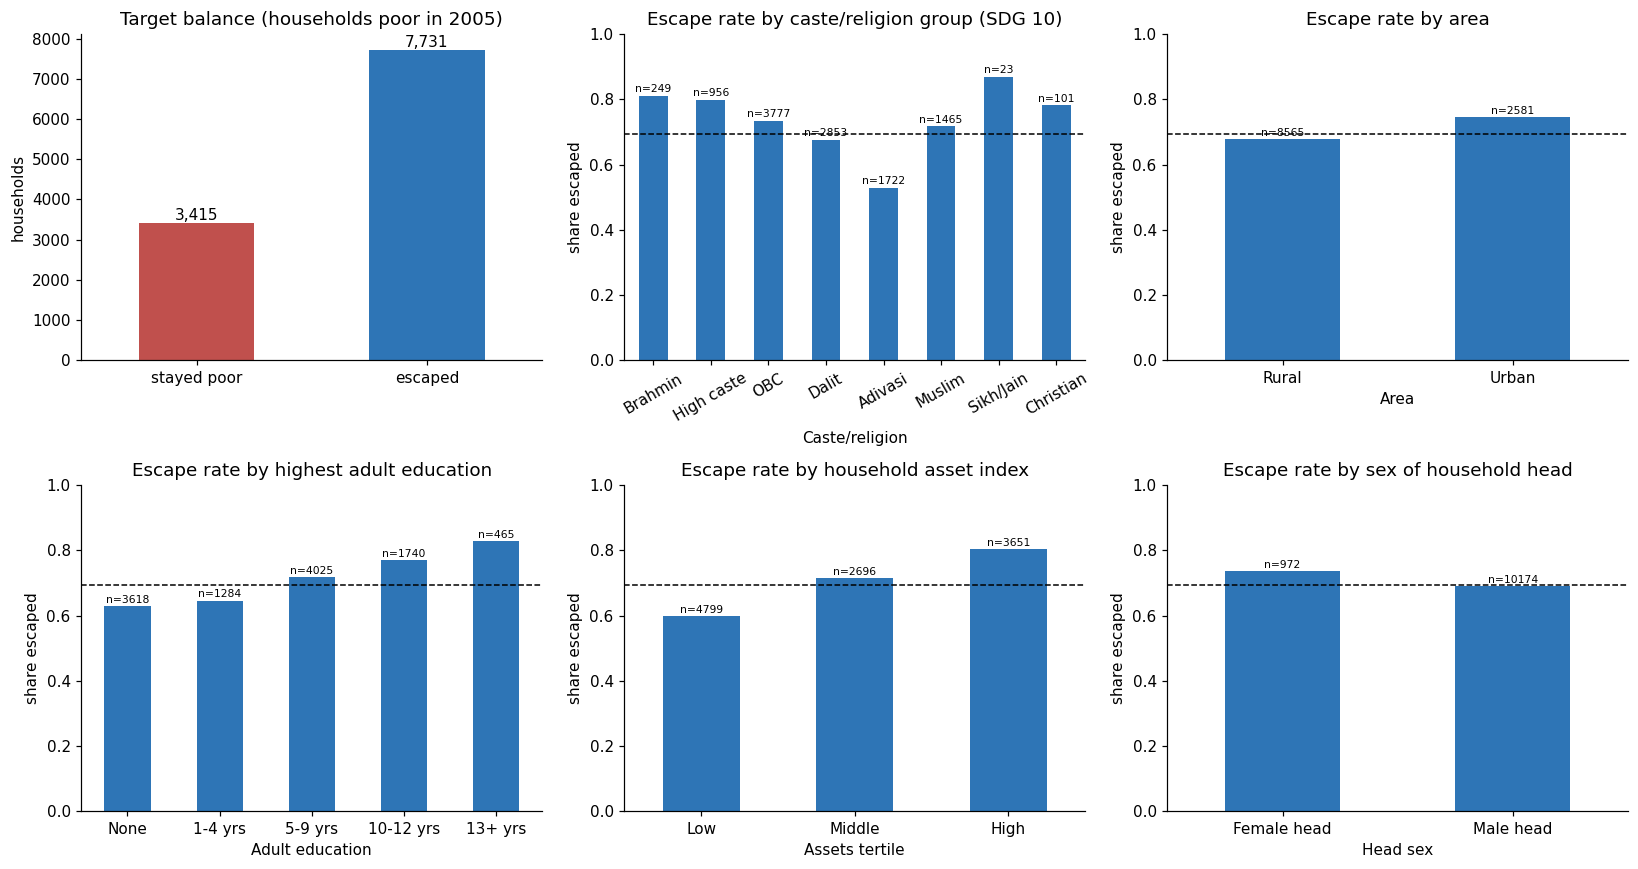

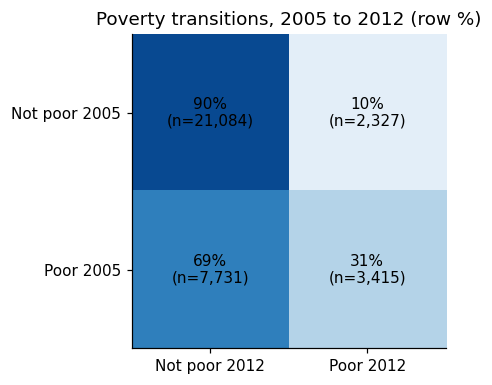

In [19]:
# Names of the 8 caste/religion groups (from the survey codebook).
GROUP_NAMES = {1: "Brahmin", 2: "High caste", 3: "OBC", 4: "Dalit", 5: "Adivasi",
               6: "Muslim", 7: "Sikh/Jain", 8: "Christian"}

# A copy of the modelling table used only for charts.
chart_data = data.copy()
overall_rate = chart_data["ESCAPED"].mean()


def plot_escape_rate(column, axis, title, order=None, rotation=30):
    """Draw a bar chart of the escape rate for each value of `column`.

    Input : column - name of the grouping column in chart_data.
            axis   - the matplotlib axis to draw on.
            title  - chart title.
            order  - optional list with the order of the bars.
            rotation - angle of the bar labels.
    Output: nothing; the bars are drawn on `axis` with the group size (n) written above each bar.
    """
    summary = chart_data.groupby(column)["ESCAPED"].agg(["mean", "size"])
    if order is not None:
        summary = summary.reindex(order)
    summary["mean"].plot.bar(ax=axis, color="#2e75b6", rot=rotation)
    axis.set_title(title)
    axis.set_ylabel("share escaped")
    axis.set_ylim(0, 1)
    axis.axhline(overall_rate, color="k", ls="--", lw=1)
    for position, (rate, size) in enumerate(zip(summary["mean"], summary["size"])):
        axis.text(position, rate + 0.01, f"n={int(size)}", ha="center", fontsize=7)


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

# Chart 1: how many households escaped and how many stayed poor.
target_balance.reindex(["stayed poor", "escaped"]).plot.bar(ax=axes[0], color=["#c0504d", "#2e75b6"], rot=0)
axes[0].set_title("Target balance (households poor in 2005)")
axes[0].set_xlabel("")
axes[0].set_ylabel("households")
for bar in axes[0].patches:
    axes[0].annotate(f"{int(bar.get_height()):,}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     ha="center", va="bottom")

# Chart 2: caste / religion group (SDG 10).
chart_data["Caste/religion"] = chart_data["GROUPS8"].map(GROUP_NAMES)
plot_escape_rate("Caste/religion", axes[1], "Escape rate by caste/religion group (SDG 10)",
                 order=[GROUP_NAMES[i] for i in range(1, 9)])

# Chart 3: rural or urban.
chart_data["Area"] = chart_data["URBAN"].map({0: "Rural", 1: "Urban"})
plot_escape_rate("Area", axes[2], "Escape rate by area", rotation=0)

# Chart 4: highest education of any adult in the household.
chart_data["Adult education"] = pd.cut(chart_data["HHED5ADULT"], [-1, 0, 4, 9, 12, 30],
                                       labels=["None", "1-4 yrs", "5-9 yrs", "10-12 yrs", "13+ yrs"])
plot_escape_rate("Adult education", axes[3], "Escape rate by highest adult education", rotation=0)

# Chart 5: asset index split into three equal groups.
chart_data["Assets tertile"] = pd.qcut(chart_data["HHASSETS"], 3, labels=["Low", "Middle", "High"], duplicates="drop")
plot_escape_rate("Assets tertile", axes[4], "Escape rate by household asset index", rotation=0)

# Chart 6: sex of the household head.
chart_data["Head sex"] = chart_data["head_female"].map({0.0: "Male head", 1.0: "Female head"})
plot_escape_rate("Head sex", axes[5], "Escape rate by sex of household head", rotation=0)

save_figure("eda_overview.png")
plt.show()

# Heat-map of poverty transitions between 2005 and 2012.
fig, axis = plt.subplots(figsize=(4.6, 3.6))
axis.imshow(transition_share.values, cmap="Blues", vmin=0, vmax=1)
for row in range(2):
    for col in range(2):
        text = f"{transition_share.values[row, col]:.0%}\n(n={transition_counts.values[row, col]:,})"
        axis.text(col, row, text, ha="center", va="center")
axis.set_xticks([0, 1])
axis.set_xticklabels(transition_counts.columns)
axis.set_yticks([0, 1])
axis.set_yticklabels(transition_counts.index)
axis.set_title("Poverty transitions, 2005 to 2012 (row %)")
save_figure("transition_matrix.png")
plt.show()

## 6. Train / test split and cross-validation

Households in the same village or neighbourhood share prices, services and local shocks. A random split would put some of a village in train and some in test, and the test score would look better than it should.

So the **20% test set is chosen by village (PSU)**: a village is either fully in train or fully in test. All tuning uses **5-fold cross-validation by village on the training part only**. The test set is never used to choose models, settings or the decision threshold; it is used only to report the final scores (and for the checks in Sections 9 and 10).

In [20]:
# Split by village: 80% of villages for training, 20% for testing.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))

# Build the train and test parts of inputs, target and village ids.
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train, groups_test = groups[train_idx], groups[test_idx]

# Safety check: no village appears in both parts.
assert not set(groups_train) & set(groups_test), "village leakage between train and test"

def stable_group_folds(group_ids, n_splits=5, seed=SEED):
    """Build cross-validation folds that keep whole villages together, the same way on every computer.

    scikit-learn's GroupKFold breaks ties between villages of equal size in a way that changed between versions,
    so the folds (and the tuned settings) differed from one installation to another. This function is deterministic:
    villages are sorted by size (largest first, ties broken by a seeded random order) and each village goes to the
    fold that currently holds the fewest households.

    Input : group_ids - array with the village id of each row; n_splits - number of folds; seed - tie-break seed.
    Output: list of (train_rows, validation_rows) pairs; every row is in exactly one validation part.
    """
    group_ids = np.asarray(group_ids)
    villages, inverse, sizes = np.unique(group_ids, return_inverse=True, return_counts=True)
    tie_break = np.random.RandomState(seed).permutation(len(villages))
    order = np.lexsort((tie_break, -sizes))
    fold_load = np.zeros(n_splits, dtype=int)
    fold_of_village = np.zeros(len(villages), dtype=int)
    for village in order:
        target_fold = int(np.argmin(fold_load))
        fold_of_village[village] = target_fold
        fold_load[target_fold] += sizes[village]
    fold_of_row = fold_of_village[inverse]
    return [(np.where(fold_of_row != fold)[0], np.where(fold_of_row == fold)[0]) for fold in range(n_splits)]


# Cross-validation folds that keep whole villages together (deterministic, saved at the end for reproducibility).
cv = stable_group_folds(groups_train, n_splits=5)

print(f"Train: {len(X_train):,} households in {len(set(groups_train)):,} villages | "
      f"Test: {len(X_test):,} in {len(set(groups_test)):,} villages")
print(f"Escape rate: train {y_train.mean():.1%} | test {y_test.mean():.1%}")
REPORT_NUMBERS.update(n_train=len(X_train), n_test=len(X_test), n_train_villages=len(set(groups_train)), n_test_villages=len(set(groups_test)))

Train: 8,894 households in 1,586 villages | Test: 2,252 in 397 villages
Escape rate: train 69.4% | test 69.2%


## 7. Models

**Why these models**
- **Logistic Regression:** simple, easy to read, gives well-behaved probabilities. A good baseline.
- **Random Forest** and **XGBoost:** many decision trees combined. They can find curved patterns and interactions that a straight-line model misses.
- **Soft-vote ensemble:** the average of the three models' probabilities.
- **Dummy:** always predicts the overall rate. It shows what "no skill" looks like.

**Pre-processing (inside every cross-validation step, so nothing leaks from the hidden part):**
cut extreme numbers (0.5th to 99.5th percentile, because a few cells contain typing errors such as `100` meals a day) -> fill empty numbers with the median -> (scale numbers, Logistic Regression only) -> one-hot encode category codes (categories under 1% are grouped).

**Class balance.** About two thirds of the households escaped, so the classes are mildly unbalanced. We do **not** use class weights: weights pull the predicted probabilities away from the real rates. The main score is **ROC-AUC**, which does not depend on the class ratio. The decision threshold is chosen on *cross-validated training predictions* to maximise **macro-F1** (the average F1 of both classes), never on the test set. Section 8 reports calibration.

**Tuning.** `RandomizedSearchCV` tries many settings and keeps the one with the best cross-validated ROC-AUC (cross-validation by village, folds from `stable_group_folds`).

In [21]:
# ClipOutliers is defined in ihds_tools.py (next to this notebook) so that saved models can be reloaded by the demo app.
from ihds_tools import ClipOutliers


def make_preprocessor(scale, numeric_columns=None):
    """Create the pre-processing step that is used in front of every model.

    Numeric columns : cut extremes -> fill empty values with the median -> (optional) scale to mean 0, sd 1.
    Category columns: one-hot encode (one yes/no column per category; rare categories are grouped).

    Input : scale           - True for Logistic Regression (it needs scaled numbers), False for tree models.
            numeric_columns - list of numeric columns to use; the default is the global NUMERIC list.
    Output: a ColumnTransformer that can be placed in a Pipeline.
    """
    if numeric_columns is None:
        numeric_columns = NUMERIC
    numeric_steps = [("clip", ClipOutliers()), ("fill", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    one_hot = OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False)
    return ColumnTransformer([("num", Pipeline(numeric_steps), numeric_columns),
                              ("cat", one_hot, NOMINAL)])

In [22]:
# ---- Model 1: Logistic Regression (settings to try: strength of regularisation C) ----
logistic_pipeline = Pipeline([("prep", make_preprocessor(scale=True)),
                              ("clf", LogisticRegression(max_iter=3000))])
logistic_grid = {"clf__C": np.logspace(-4, 1, 11)}

# ---- Model 2: Random Forest ----
forest_pipeline = Pipeline([("prep", make_preprocessor(scale=False)),
                            ("clf", RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=1))])
forest_grid = {"clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": [1, 3, 5, 10, 20],
               "clf__max_features": ["sqrt", 0.2, 0.4]}

# ---- Model 3: XGBoost ----
xgboost_pipeline = Pipeline([("prep", make_preprocessor(scale=False)),
                             ("clf", XGBClassifier(eval_metric="logloss",
                                                   tree_method="hist", random_state=SEED, n_jobs=1))])
xgboost_grid = {"clf__n_estimators": [200, 400, 600], "clf__learning_rate": [0.02, 0.05, 0.1],
                "clf__max_depth": [2, 3, 4, 5, 6], "clf__min_child_weight": [1, 3, 5, 10],
                "clf__subsample": [0.7, 0.85, 1.0], "clf__colsample_bytree": [0.5, 0.7, 0.9],
                "clf__reg_lambda": [1, 5, 10]}

# All models with their settings grid, and how many random settings to try for each.
MODEL_SETUP = {"Logistic Regression": (logistic_pipeline, logistic_grid),
               "Random Forest": (forest_pipeline, forest_grid),
               "XGBoost": (xgboost_pipeline, xgboost_grid)}
SETTINGS_TO_TRY = {"Logistic Regression": 11, "Random Forest": 20, "XGBoost": 30}

best_models = {}      # the tuned model of each type
cv_rows = []          # cross-validation summary rows

for model_name, (pipeline, grid) in MODEL_SETUP.items():
    model_start = time.time()

    # Try random settings, score each with 5-fold village CV, and refit the best one on all training data.
    search = RandomizedSearchCV(pipeline, grid, n_iter=SETTINGS_TO_TRY[model_name], scoring="roc_auc",
                                cv=cv, random_state=SEED, n_jobs=-1, refit=True)
    search.fit(X_train, y_train, groups=groups_train)
    best_models[model_name] = search.best_estimator_

    # Record the cross-validated score of the best settings.
    best = search.best_index_
    cv_mean = search.cv_results_["mean_test_score"][best]
    cv_sd = search.cv_results_["std_test_score"][best]
    best_settings = {key.replace("clf__", ""): value for key, value in search.best_params_.items()}
    cv_rows.append({"Model": model_name, "CV ROC-AUC (mean)": cv_mean, "CV ROC-AUC (sd)": cv_sd,
                    "Best params": best_settings})
    print(f"{model_name:20s} CV ROC-AUC {cv_mean:.4f} +/- {cv_sd:.4f}  ({time.time() - model_start:.0f}s)  {search.best_params_}")

cv_summary = pd.DataFrame(cv_rows)
display(cv_summary)
cv_summary.to_csv(OUTPUT_DIR / "cv_summary.csv", index=False)

Logistic Regression  CV ROC-AUC 0.6876 +/- 0.0130  (34s)  {'clf__C': np.float64(0.1)}


Random Forest        CV ROC-AUC 0.6849 +/- 0.0195  (551s)  {'clf__min_samples_leaf': 3, 'clf__max_features': 0.4, 'clf__max_depth': 12}


XGBoost              CV ROC-AUC 0.6964 +/- 0.0160  (133s)  {'clf__subsample': 0.85, 'clf__reg_lambda': 5, 'clf__n_estimators': 600, 'clf__min_child_weight': 10, 'clf__max_depth': 5, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.7}


,Model,CV ROC-AUC (mean),CV ROC-AUC (sd),Best params
0,Logistic Regression,0.687575,0.013041,{'C': 0.1}
1,Random Forest,0.684924,0.019491,"{'min_samples_leaf': 3, 'max_features': 0.4, '..."
2,XGBoost,0.696403,0.016026,"{'subsample': 0.85, 'reg_lambda': 5, 'n_estima..."


### Feature selection check

We chose the 137 features by domain knowledge (ten groups) and by simple rules (no spending or income, no more than 40% missing).
Do we really need all of them? We rank the features by their importance in the XGBoost model fitted on the **training villages only**,
keep only the top 10, 20, 40 or 80, refit XGBoost with the same settings and compare the scores.


,Cross-validated ROC-AUC,Test ROC-AUC
Features kept,,
10,0.6638,0.6928
20,0.6861,0.7080
40,0.6935,0.7169
80,0.6991,0.7211
137,0.6964,0.7220


Top 10 features by training importance: ['STATEID2', 'GROUPS8', 'ID13', 'ID15', 'HQ5', 'HQ6', 'HQ4', 'HQ1', 'FU9', 'HHASSETS']


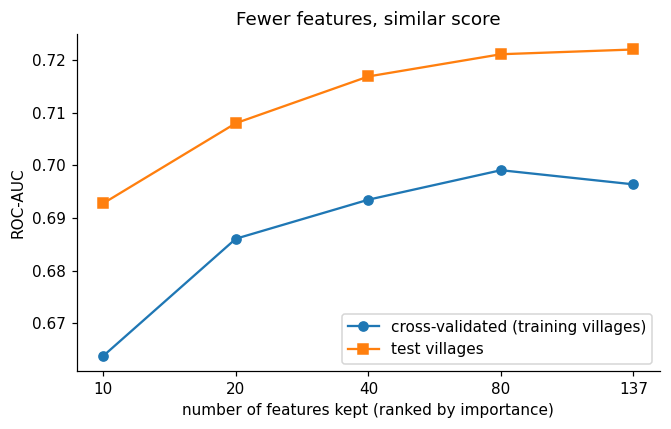

In [23]:
# ---- Feature selection check: do we really need all 137 features? ----
# Step 1: rank the features by their importance in the XGBoost model that was fitted on the TRAINING villages only.
fitted_xgboost = best_models["XGBoost"]
encoded_feature_names = [name.split("__", 1)[1] for name in fitted_xgboost.named_steps["prep"].get_feature_names_out()]


def variable_of(encoded_name):
    """Survey variable that an encoded column belongs to (for example GROUPS8_5 belongs to GROUPS8)."""
    for name in sorted(NOMINAL, key=len, reverse=True):
        if encoded_name == name or encoded_name.startswith(name + "_"):
            return name
    return encoded_name


train_importance = pd.Series(fitted_xgboost.named_steps["clf"].feature_importances_, index=encoded_feature_names)
ranked_variables = list(train_importance.groupby(variable_of).sum().sort_values(ascending=False).index)


def preprocessor_for(numeric_columns, nominal_columns):
    """Same pre-processing as before (cap outliers, fill gaps with the median, one-hot encode) for a chosen set of columns."""
    numeric_steps = [("clip", ClipOutliers()), ("fill", SimpleImputer(strategy="median"))]
    one_hot = OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False)
    return ColumnTransformer([("num", Pipeline(numeric_steps), numeric_columns), ("cat", one_hot, nominal_columns)])


# Step 2: keep only the top k features, refit XGBoost (same settings) and score it.
selection_rows = []
for keep_count in [10, 20, 40, 80, len(ranked_variables)]:
    kept = ranked_variables[:keep_count]
    numeric_kept = [name for name in NUMERIC if name in kept]
    nominal_kept = [name for name in NOMINAL if name in kept]
    model_k = clone(fitted_xgboost).set_params(prep=preprocessor_for(numeric_kept, nominal_kept))
    columns_kept = numeric_kept + nominal_kept
    cv_auc = cross_val_score(model_k, X_train[columns_kept], y_train, cv=cv, scoring="roc_auc").mean()
    test_auc = roc_auc_score(y_test, clone(model_k).fit(X_train[columns_kept], y_train).predict_proba(X_test[columns_kept])[:, 1])
    selection_rows.append({"Features kept": keep_count, "Cross-validated ROC-AUC": cv_auc, "Test ROC-AUC": test_auc})
selection_table = pd.DataFrame(selection_rows).set_index("Features kept")
display(selection_table.round(4))
selection_table.round(4).to_csv(OUTPUT_DIR / "feature_selection.csv")
print("Top 10 features by training importance:", ranked_variables[:10])

fig, axis = plt.subplots(figsize=(6.2, 4))
axis.plot(selection_table.index.astype(str), selection_table["Cross-validated ROC-AUC"], "o-", label="cross-validated (training villages)")
axis.plot(selection_table.index.astype(str), selection_table["Test ROC-AUC"], "s-", label="test villages")
axis.set_xlabel("number of features kept (ranked by importance)")
axis.set_ylabel("ROC-AUC")
axis.set_title("Fewer features, similar score")
axis.legend()
save_figure("feature_selection.png")
plt.show()

REPORT_NUMBERS["feature_selection"] = {"table": selection_table.round(4).reset_index().to_dict("records"), "top10": ranked_variables[:10]}


## 8. Test-set results

All scores in this section come from the **held-out villages**. "Escaped" is the positive class.

For a welfare scheme the "stayed poor" households matter most, so we report precision and recall for **both** classes, plus macro-F1, next to ROC-AUC.

The 95% confidence intervals use a **village bootstrap**: we re-draw whole villages many times and see how much the score moves. This respects the fact that households in one village are alike.

In [24]:
def out_of_fold_probabilities(model):
    """Predict P(escape) for every TRAINING household using cross-validation.

    Each household is predicted by a model that did not see its village during training,
    so the predictions are honest. They are used to choose the decision threshold.

    Input : model - a model pipeline (it is cloned, the original is not changed).
    Output: array with one probability per training household.
    """
    probabilities = cross_val_predict(clone(model), X_train, y_train, cv=cv, groups=groups_train,
                                      method="predict_proba", n_jobs=-1)
    return probabilities[:, 1]


def pick_threshold(y_true, probabilities):
    """Find the probability cut-off that gives the best macro-F1.

    Try cut-offs from 0.05 to 0.95 and keep the one where the average F1 of both classes is highest.

    Input : y_true - real outcomes (0/1); probabilities - predicted P(escape).
    Output: the best cut-off as a number between 0.05 and 0.95.
    """
    cutoffs = np.linspace(0.05, 0.95, 181)
    scores = []
    for cutoff in cutoffs:
        predicted = (probabilities >= cutoff).astype(int)
        scores.append(f1_score(y_true, predicted, average="macro"))
    return float(cutoffs[np.argmax(scores)])


def score_predictions(y_true, probabilities, threshold):
    """Calculate all evaluation scores for one model.

    Input : y_true        - real outcomes (1 = escaped, 0 = stayed poor).
            probabilities - predicted P(escape).
            threshold     - cut-off above which a household is predicted to escape.
    Output: dictionary of scores: ROC-AUC, PR-AUC (both classes), Brier score, accuracy, balanced accuracy,
            macro-F1, MCC, and precision/recall for both classes.
    """
    predicted = (probabilities >= threshold).astype(int)
    return {
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC_escaped": average_precision_score(y_true, probabilities),
        "PR_AUC_stayed_poor": average_precision_score(1 - y_true, 1 - probabilities),
        "Brier": brier_score_loss(y_true, probabilities),
        "Accuracy": accuracy_score(y_true, predicted),
        "Balanced_acc": balanced_accuracy_score(y_true, predicted),
        "Macro_F1": f1_score(y_true, predicted, average="macro"),
        "MCC": matthews_corrcoef(y_true, predicted),
        "Precision_escaped": precision_score(y_true, predicted, zero_division=0),
        "Recall_escaped": recall_score(y_true, predicted),
        "Precision_stayed": precision_score(1 - y_true, 1 - predicted, zero_division=0),
        "Recall_stayed": recall_score(1 - y_true, 1 - predicted),
        "Threshold": threshold,
    }


# Predicted probabilities: on the test set, and out-of-fold on the training set.
test_probs = {}
oof_probs = {}
for model_name, model in best_models.items():
    oof_probs[model_name] = out_of_fold_probabilities(model)
    test_probs[model_name] = model.predict_proba(X_test)[:, 1]

# Ensemble = simple average of the three models' probabilities.
ENSEMBLE = "Soft-vote ensemble (LR+RF+XGB)"
oof_probs[ENSEMBLE] = np.mean([oof_probs[name] for name in best_models], axis=0)
test_probs[ENSEMBLE] = np.mean([test_probs[name] for name in best_models], axis=0)

# For each model: choose the threshold on training predictions, then score on the test set.
thresholds = {}
result_rows = []
for model_name in test_probs:
    thresholds[model_name] = pick_threshold(y_train, oof_probs[model_name])
    scores = score_predictions(y_test, test_probs[model_name], thresholds[model_name])
    result_rows.append({"Model": model_name, **scores})

# Dummy baseline: always predicts the training escape rate (tiny noise only breaks ties for the AUC).
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
dummy_probs = dummy.predict_proba(X_test)[:, 1] + np.random.RandomState(0).normal(0, 1e-9, len(y_test))
result_rows.append({"Model": "Dummy (predict prior)", **score_predictions(y_test, dummy_probs, 0.5)})
results = pd.DataFrame(result_rows).set_index("Model")

In [25]:
def draw_village_bootstrap_sample(rows_by_village, villages, rng):
    """Draw one bootstrap sample made of whole villages.

    Villages are drawn with replacement (a village can appear twice or not at all);
    all households of a drawn village are included.

    Input : rows_by_village - dictionary {village id: array of row numbers}.
            villages        - array of all village ids.
            rng             - numpy random generator.
    Output: array of row numbers that form the bootstrap sample.
    """
    chosen_villages = rng.choice(villages, len(villages), replace=True)
    return np.concatenate([rows_by_village[village] for village in chosen_villages])


# Prepare 1000 bootstrap samples of test villages (the same samples are used for all models).
rng = np.random.RandomState(SEED)
test_villages = np.unique(groups_test)
test_rows_by_village = {village: np.where(groups_test == village)[0] for village in test_villages}
BOOTSTRAP_SAMPLES = [draw_village_bootstrap_sample(test_rows_by_village, test_villages, rng) for _ in range(1000)]


def bootstrap_interval(metric_function):
    """95% confidence interval of a score, using the bootstrap samples above.

    Input : metric_function - a function that takes the row numbers of one sample and returns a number.
    Output: (lower, upper) = the 2.5th and 97.5th percentile of the score over all samples.
    """
    values = np.array([metric_function(rows) for rows in BOOTSTRAP_SAMPLES])
    return np.percentile(values, [2.5, 97.5])


# 95% confidence interval of the ROC-AUC of every model.
for model_name in test_probs:
    probs = test_probs[model_name]
    low, high = bootstrap_interval(lambda rows: roc_auc_score(y_test[rows], probs[rows]))
    results.loc[model_name, "ROC_AUC_CI"] = f"[{low:.3f}, {high:.3f}]"

# Sort by ROC-AUC, show and save the table.
results = results.sort_values("ROC_AUC", ascending=False)
display(results.round(4))
results.round(4).to_csv(OUTPUT_DIR / "model_comparison.csv")

# Headline model, chosen BEFORE looking at the test set: the single model with the best cross-validated ROC-AUC (Section 7).
best_single_name = cv_summary.set_index("Model")["CV ROC-AUC (mean)"].idxmax()
best_model_name = best_single_name
print("Headline model (best cross-validated AUC):", best_model_name)
print("Highest test AUC:", results.drop(index="Dummy (predict prior)").index[0], "(not used to choose the headline model)")


def auc_difference(model_a, model_b):
    """Is model A really better than model B? Compare their ROC-AUC on the bootstrap samples.

    Input : names of two models in test_probs.
    Output: (AUC of A minus AUC of B, lower and upper end of its 95% interval).
            If the interval contains 0, the two models cannot be told apart.
    """
    low, high = bootstrap_interval(lambda rows: roc_auc_score(y_test[rows], test_probs[model_a][rows])
                                   - roc_auc_score(y_test[rows], test_probs[model_b][rows]))
    difference = roc_auc_score(y_test, test_probs[model_a]) - roc_auc_score(y_test, test_probs[model_b])
    return difference, low, high


paired_differences = []
for model_a, model_b in [("XGBoost", "Logistic Regression"), ("Random Forest", "Logistic Regression"),
                         ("XGBoost", "Random Forest"), (ENSEMBLE, "Logistic Regression"),
                         (ENSEMBLE, "XGBoost"), (ENSEMBLE, "Random Forest")]:
    difference, low, high = auc_difference(model_a, model_b)
    print(f"AUC({model_a}) - AUC({model_b}) = {difference:+.4f}  95% CI [{low:+.4f}, {high:+.4f}]")
    paired_differences.append({"model_a": model_a, "model_b": model_b, "difference": float(difference),
                               "ci_low": float(low), "ci_high": float(high)})

REPORT_NUMBERS.update(paired_differences=paired_differences, best_model=best_model_name, best_single=best_single_name,
                      results=results.round(4).reset_index().to_dict("records"))

,ROC_AUC,PR_AUC_escaped,PR_AUC_stayed_poor,Brier,Accuracy,Balanced_acc,Macro_F1,MCC,Precision_escaped,Recall_escaped,Precision_stayed,Recall_stayed,Threshold,ROC_AUC_CI
Model,,,,,,,,,,,,,,
XGBoost,0.7220,0.8441,0.5561,0.1833,0.6963,0.6596,0.6541,0.3103,0.7958,0.7550,0.5058,0.5642,0.645,"[0.694, 0.750]"
Soft-vote ensemble (LR+RF+XGB),0.7187,0.8411,0.5546,0.1842,0.6949,0.6494,0.6471,0.2947,0.7865,0.7678,0.5041,0.5310,0.635,"[0.689, 0.747]"
Random Forest,0.7087,0.8363,0.5362,0.1871,0.6927,0.6482,0.6455,0.2916,0.7861,0.7640,0.5007,0.5325,0.650,"[0.679, 0.738]"
Logistic Regression,0.6998,0.8260,0.5266,0.1889,0.6776,0.6433,0.6364,0.2764,0.7870,0.7325,0.4794,0.5541,0.640,"[0.670, 0.730]"
Dummy (predict prior),0.4870,0.6911,0.3052,0.2130,0.6923,0.5000,0.4091,0.0000,0.6923,1.0000,0.0000,0.0000,0.500,NaN


Headline model (best cross-validated AUC): XGBoost
Highest test AUC: XGBoost (not used to choose the headline model)


AUC(XGBoost) - AUC(Logistic Regression) = +0.0222  95% CI [+0.0099, +0.0346]


AUC(Random Forest) - AUC(Logistic Regression) = +0.0089  95% CI [-0.0069, +0.0252]


AUC(XGBoost) - AUC(Random Forest) = +0.0133  95% CI [+0.0026, +0.0238]


AUC(Soft-vote ensemble (LR+RF+XGB)) - AUC(Logistic Regression) = +0.0189  95% CI [+0.0107, +0.0273]


AUC(Soft-vote ensemble (LR+RF+XGB)) - AUC(XGBoost) = -0.0033  95% CI [-0.0091, +0.0019]


AUC(Soft-vote ensemble (LR+RF+XGB)) - AUC(Random Forest) = +0.0100  95% CI [+0.0009, +0.0188]


### Every model on every metric

The table above shows the main scores. The next table adds accuracy, precision, recall and F1 for **both** classes, and the
confusion matrix of **every** model, all on the same test villages and with each model's own threshold.


,Accuracy,Precision (escaped),Recall (escaped),F1 (escaped),Precision (stayed poor),Recall (stayed poor),F1 (stayed poor),Macro-F1,ROC-AUC,True stayed,False escaped,False stayed,True escaped
Model,,,,,,,,,,,,,
Logistic Regression,0.678,0.787,0.733,0.759,0.479,0.554,0.514,0.636,0.700,384,309,417,1142
Random Forest,0.693,0.786,0.764,0.775,0.501,0.532,0.516,0.645,0.709,369,324,368,1191
XGBoost,0.696,0.796,0.755,0.775,0.506,0.564,0.533,0.654,0.722,391,302,382,1177
Soft-vote ensemble (LR+RF+XGB),0.695,0.786,0.768,0.777,0.504,0.531,0.517,0.647,0.719,368,325,362,1197


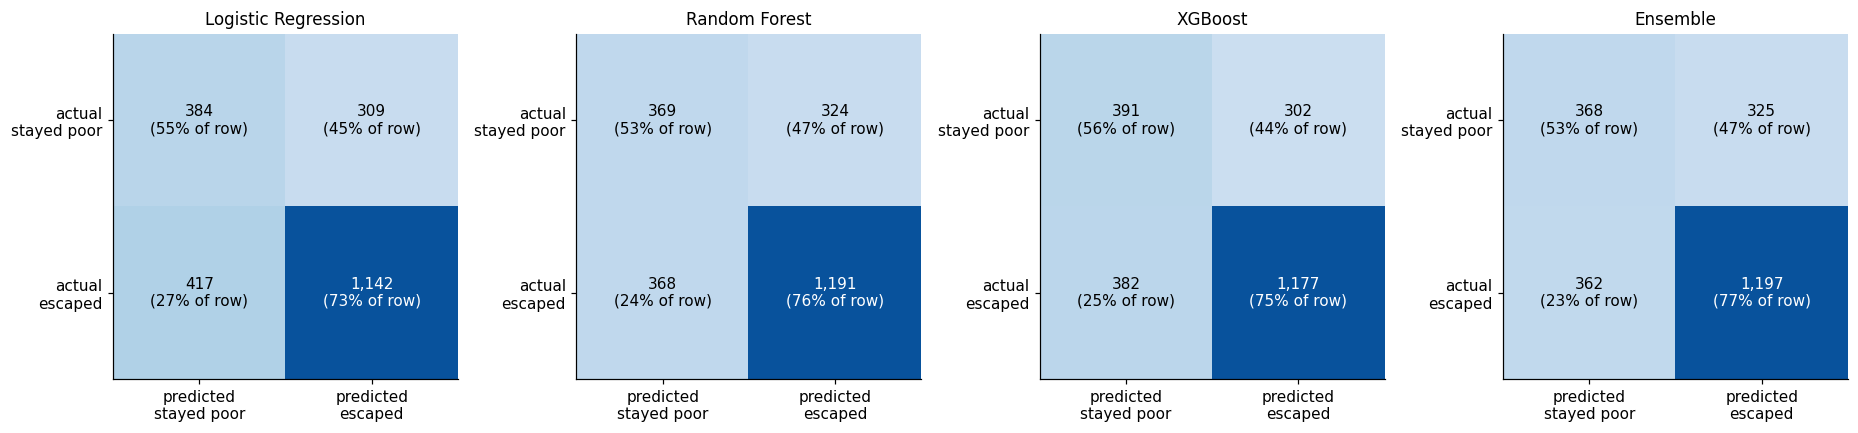

In [26]:
# ---- Full comparison table: accuracy, precision, recall, F1 (both classes), ROC-AUC and confusion matrix for EVERY model ----
MODEL_ORDER = ["Logistic Regression", "Random Forest", "XGBoost", ENSEMBLE]
metric_rows, confusion_by_model = [], {}
for model_name in MODEL_ORDER:
    predicted = (test_probs[model_name] >= thresholds[model_name]).astype(int)
    true_neg, false_pos, false_neg, true_pos = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
    precision_escaped = true_pos / (true_pos + false_pos)
    recall_escaped = true_pos / (true_pos + false_neg)
    precision_stayed = true_neg / (true_neg + false_neg)
    recall_stayed = true_neg / (true_neg + false_pos)
    f1_escaped = 2 * precision_escaped * recall_escaped / (precision_escaped + recall_escaped)
    f1_stayed = 2 * precision_stayed * recall_stayed / (precision_stayed + recall_stayed)
    metric_rows.append({"Model": model_name, "Accuracy": (true_pos + true_neg) / len(y_test),
                        "Precision (escaped)": precision_escaped, "Recall (escaped)": recall_escaped, "F1 (escaped)": f1_escaped,
                        "Precision (stayed poor)": precision_stayed, "Recall (stayed poor)": recall_stayed, "F1 (stayed poor)": f1_stayed,
                        "Macro-F1": (f1_escaped + f1_stayed) / 2, "ROC-AUC": results.loc[model_name, "ROC_AUC"],
                        "True stayed": int(true_neg), "False escaped": int(false_pos),
                        "False stayed": int(false_neg), "True escaped": int(true_pos)})
    confusion_by_model[model_name] = [[int(true_neg), int(false_pos)], [int(false_neg), int(true_pos)]]
full_metrics = pd.DataFrame(metric_rows).set_index("Model")

# Safety check: the hand-made numbers must agree with the table above.
for model_name in MODEL_ORDER:
    assert abs(full_metrics.loc[model_name, "Macro-F1"] - results.loc[model_name, "Macro_F1"]) < 1e-9
    assert abs(full_metrics.loc[model_name, "Precision (escaped)"] - results.loc[model_name, "Precision_escaped"]) < 1e-9
display(full_metrics.round(3))
full_metrics.round(4).to_csv(OUTPUT_DIR / "model_full_metrics.csv")

# Confusion matrix of every model on the test villages.
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for axis, model_name in zip(axes, MODEL_ORDER):
    matrix = np.array(confusion_by_model[model_name])
    axis.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max() * 1.15)
    for row in range(2):
        for col in range(2):
            axis.text(col, row, f"{matrix[row, col]:,}\n({matrix[row, col] / matrix[row].sum():.0%} of row)", ha="center", va="center",
                      color="white" if matrix[row, col] > matrix.max() / 2 else "black")
    axis.set_xticks([0, 1])
    axis.set_xticklabels(["predicted\nstayed poor", "predicted\nescaped"])
    axis.set_yticks([0, 1])
    axis.set_yticklabels(["actual\nstayed poor", "actual\nescaped"])
    axis.set_title(model_name.replace("Soft-vote ensemble (LR+RF+XGB)", "Ensemble"), fontsize=11)
save_figure("confusion_matrices_all_models.png")
plt.show()

REPORT_NUMBERS["full_metrics"] = full_metrics.round(4).reset_index().to_dict("records")
REPORT_NUMBERS["confusion_matrices"] = confusion_by_model


### Overfitting check

A model that scores much better on the households it learned from than on new villages is overfitting.
The table compares the score on the training households, in cross-validation and on the test villages.


In [27]:
# ---- Overfitting check: is the score on the data a model learned from much higher than on new villages? ----
cv_scores = cv_summary.set_index("Model")["CV ROC-AUC (mean)"]
overfit_rows = []
for model_name in ["Logistic Regression", "Random Forest", "XGBoost"]:
    overfit_rows.append({"Model": model_name,
                         "Train ROC-AUC": roc_auc_score(y_train, best_models[model_name].predict_proba(X_train)[:, 1]),
                         "Cross-validated ROC-AUC": cv_scores[model_name],
                         "Test ROC-AUC": results.loc[model_name, "ROC_AUC"]})
overfit_table = pd.DataFrame(overfit_rows).set_index("Model")
display(overfit_table.round(3))
overfit_table.round(4).to_csv(OUTPUT_DIR / "overfitting_check.csv")
print("Random Forest fits the training households almost perfectly (train score close to 1), which is why we judge models on cross-validation and on test villages only.")
REPORT_NUMBERS["overfitting_check"] = overfit_table.round(4).reset_index().to_dict("records")


,Train ROC-AUC,Cross-validated ROC-AUC,Test ROC-AUC
Model,,,
Logistic Regression,0.731,0.688,0.700
Random Forest,0.988,0.685,0.709
XGBoost,0.851,0.696,0.722


Random Forest fits the training households almost perfectly (train score close to 1), which is why we judge models on cross-validation and on test villages only.


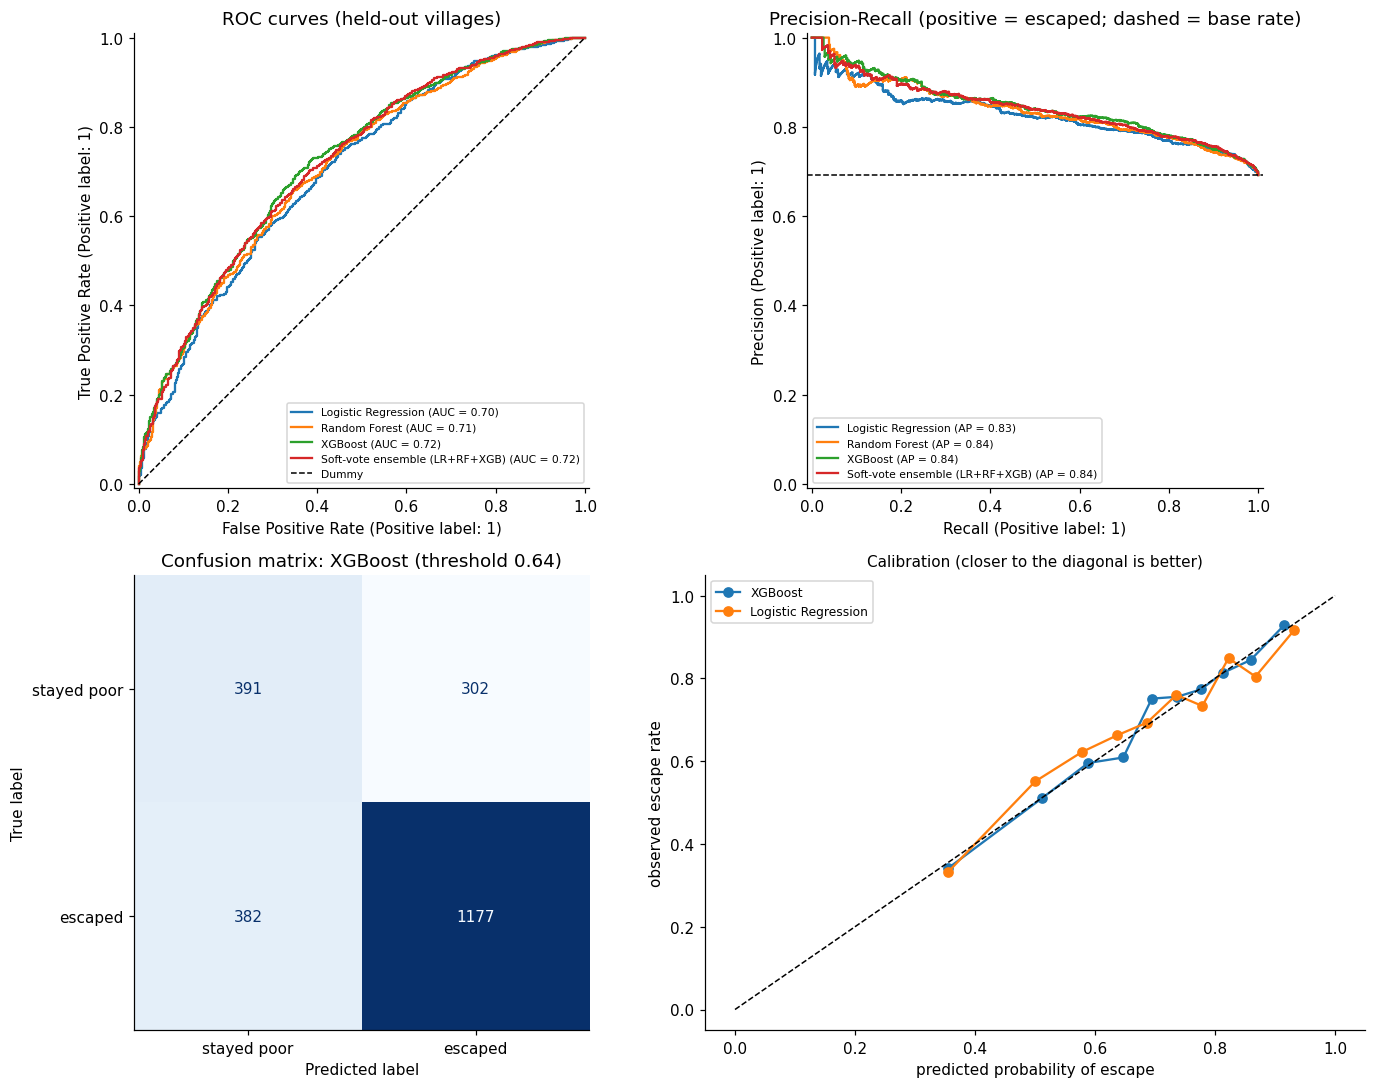

Confusion matrix rows = actual, cols = predicted (stayed poor, escaped):
[[ 391  302]
 [ 382 1177]]


In [28]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

# Top row: ROC curves and precision-recall curves for all models.
for model_name in test_probs:
    RocCurveDisplay.from_predictions(y_test, test_probs[model_name], name=model_name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, test_probs[model_name], name=model_name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Dummy")
axes[0].set_title("ROC curves (held-out villages)")
axes[0].legend(fontsize=7)
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1)
axes[1].set_title("Precision-Recall (positive = escaped; dashed = base rate)")
axes[1].legend(fontsize=7)

# Bottom left: confusion matrix of the best model.
best_predictions = (test_probs[best_model_name] >= thresholds[best_model_name]).astype(int)
confusion = confusion_matrix(y_test, best_predictions)
ConfusionMatrixDisplay(confusion, display_labels=["stayed poor", "escaped"]).plot(ax=axes[2], colorbar=False, cmap="Blues")
axes[2].set_title(f"Confusion matrix: {best_model_name} (threshold {thresholds[best_model_name]:.2f})")

# Bottom right: calibration curve = predicted probability versus what really happened.
for model_name in dict.fromkeys([best_single_name, "Logistic Regression", "XGBoost"]):
    observed, predicted = calibration_curve(y_test, test_probs[model_name], n_bins=10, strategy="quantile")
    axes[3].plot(predicted, observed, "o-", label=model_name)
axes[3].plot([0, 1], [0, 1], "k--", lw=1)
axes[3].set_xlabel("predicted probability of escape")
axes[3].set_ylabel("observed escape rate")
axes[3].set_title("Calibration (closer to the diagonal is better)", fontsize=10)
axes[3].legend(fontsize=8)

save_figure("results_overview.png")
plt.show()
print(f"Confusion matrix rows = actual, cols = predicted (stayed poor, escaped):\n{confusion}")

### From AUC to practical value: risk quintiles

A welfare scheme with a limited budget would rank poor households by their predicted risk of **staying poor** (1 minus P(escape)) and help the highest-risk group first.

The table splits the test households into five equal groups by predicted risk and shows how many in each group really stayed poor. If the model is useful, the top group should stay poor much more often than the average.

,households,stayed_poor_rate,lift_vs_average,share_of_all_stayed_poor
quintile,,,,
Q1 (lowest risk),451,0.113,0.367,0.074
Q2,450,0.207,0.672,0.134
Q3,450,0.247,0.802,0.160
Q4,450,0.398,1.293,0.258
Q5 (highest risk),451,0.574,1.866,0.374


Average rate of staying poor: 30.8%. Highest-risk 20%: 57.4% stayed poor (lift 1.87x). The highest-risk 40% contain 63.2% of everyone who stayed poor.


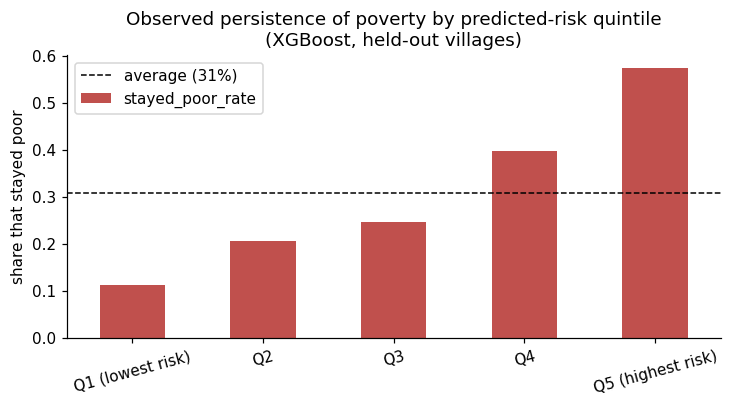

In [29]:
# Predicted risk of staying poor = 1 - probability of escaping.
risk = 1 - test_probs[best_model_name]

# Split households into five equal groups by risk (Q1 = lowest risk, Q5 = highest risk).
quintile_names = ["Q1 (lowest risk)", "Q2", "Q3", "Q4", "Q5 (highest risk)"]
quintile = pd.qcut(pd.Series(risk).rank(method="first"), 5, labels=quintile_names)

# For each group: number of households and the share that really stayed poor.
risk_table = pd.DataFrame({"stayed_poor": 1 - y_test, "quintile": quintile.values})
lift = risk_table.groupby("quintile", observed=True).agg(households=("stayed_poor", "size"),
                                                         stayed_poor_rate=("stayed_poor", "mean"))

# Lift = how many times more often than average the group stayed poor.
average_rate = float((1 - y_test).mean())
lift["lift_vs_average"] = lift["stayed_poor_rate"] / average_rate
lift["share_of_all_stayed_poor"] = lift["stayed_poor_rate"] * lift["households"] / (1 - y_test).sum()
display(lift.round(3))
lift.round(4).to_csv(OUTPUT_DIR / "risk_quintile_lift.csv")

top_group = lift.iloc[-1]
top_two_share = lift.iloc[-2:].share_of_all_stayed_poor.sum()
print(f"Average rate of staying poor: {average_rate:.1%}. Highest-risk 20%: {top_group.stayed_poor_rate:.1%} stayed poor "
      f"(lift {top_group.lift_vs_average:.2f}x). The highest-risk 40% contain {top_two_share:.1%} of everyone who stayed poor.")

# Bar chart of the observed rate per risk group.
fig, axis = plt.subplots(figsize=(6.8, 3.8))
lift["stayed_poor_rate"].plot.bar(ax=axis, color="#c0504d", rot=15)
axis.axhline(average_rate, color="k", ls="--", lw=1, label=f"average ({average_rate:.0%})")
axis.legend()
axis.set_ylabel("share that stayed poor")
axis.set_xlabel("")
axis.set_title(f"Observed persistence of poverty by predicted-risk quintile\n({best_model_name}, held-out villages)")
save_figure("risk_quintile_lift.png")
plt.show()

REPORT_NUMBERS["lift"] = lift.round(4).reset_index().assign(quintile=lambda d: d["quintile"].astype(str)).to_dict("records")

### Are the probabilities trustworthy? (calibration)

A *calibrated* model's probabilities can be read as real chances. We report the average predicted probability against the real escape rate, the **Brier score** (and how much better it is than always predicting the training rate: the *Brier skill score*), and a logistic recalibration of the model's log-odds on the test set (**slope** near 1 and **intercept** near 0 mean well calibrated).

In [30]:
def calibration_summary(y_true, probabilities):
    """Summarise how trustworthy the predicted probabilities are.

    Input : y_true - real outcomes (0/1); probabilities - predicted P(escape).
    Output: dictionary with mean predicted probability, real rate, Brier score, calibration intercept and slope.
    """
    clipped = np.clip(probabilities, 1e-4, 1 - 1e-4)
    log_odds = np.log(clipped / (1 - clipped)).reshape(-1, 1)
    recalibration = LogisticRegression(C=1e6, max_iter=1000).fit(log_odds, y_true)
    return {"mean_predicted": float(probabilities.mean()), "observed_rate": float(y_true.mean()),
            "Brier": float(brier_score_loss(y_true, probabilities)),
            "calib_intercept": float(recalibration.intercept_[0]), "calib_slope": float(recalibration.coef_[0, 0])}


# Reference: always predict the training escape rate.
brier_reference = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))
calibration_rows = []
for model_name in test_probs:
    row = calibration_summary(y_test, test_probs[model_name])
    row["Brier_skill_score"] = 1 - row["Brier"] / brier_reference
    calibration_rows.append({"Model": model_name, **row})
calibration_table = pd.DataFrame(calibration_rows).set_index("Model")
display(calibration_table.round(3))
calibration_table.round(4).to_csv(OUTPUT_DIR / "calibration_summary.csv")
REPORT_NUMBERS["calibration"] = calibration_table.round(4).reset_index().to_dict("records")


,mean_predicted,observed_rate,Brier,calib_intercept,calib_slope,Brier_skill_score
Model,,,,,,
Logistic Regression,0.689,0.692,0.189,0.098,0.881,0.113
Random Forest,0.687,0.692,0.187,-0.121,1.204,0.122
XGBoost,0.690,0.692,0.183,-0.034,1.068,0.139
Soft-vote ensemble (LR+RF+XGB),0.689,0.692,0.184,-0.094,1.160,0.135


## 9. Explaining the model (SHAP and odds ratios)

**SHAP** gives every household a "push" value for every input: positive means the input pushed the prediction toward *escape*, negative toward *staying poor*. We compute SHAP for the tuned XGBoost model on test households, add up (for each household) the one-hot columns that belong to the same survey variable, take the average size of that sum, and then add up the variables that belong to the same group.

**Important:** SHAP shows what the model *uses*. It does not prove that changing a variable would *cause* escape (see Section 11).

,mean_abs_SHAP,label,group
n_children_0_5,0.1902,Children aged 0-5,Household structure
STATEID2,0.1845,State (22 groups),Geography & social group
HHASSETS,0.1807,Household assets index (goods and housing),Assets & housing
assets_per_capita,0.1460,Asset index per household member,Assets & housing
RC1A,0.0925,Ration card type,Access to services
GROUPS8,0.0839,Caste/religion group (8 categories),Geography & social group
has_school_age_kids,0.0704,Household has children aged 6-14,Household structure
share_female,0.0664,Share of members who are female,Household structure
head_age,0.0656,Age of household head,Household structure
FU9,0.0488,LPG use,Access to services


,share_of_total_SHAP,n_variables,share_per_variable
Household structure,0.232,16,0.015
Assets & housing,0.232,34,0.007
Geography & social group,0.140,7,0.020
Access to services,0.131,16,0.008
Occupation & employment,0.095,19,0.005
Education,0.071,11,0.006
Women's status (gender),0.038,6,0.006
Social capital,0.026,15,0.002
Finance & social protection,0.023,9,0.003
Health,0.012,4,0.003


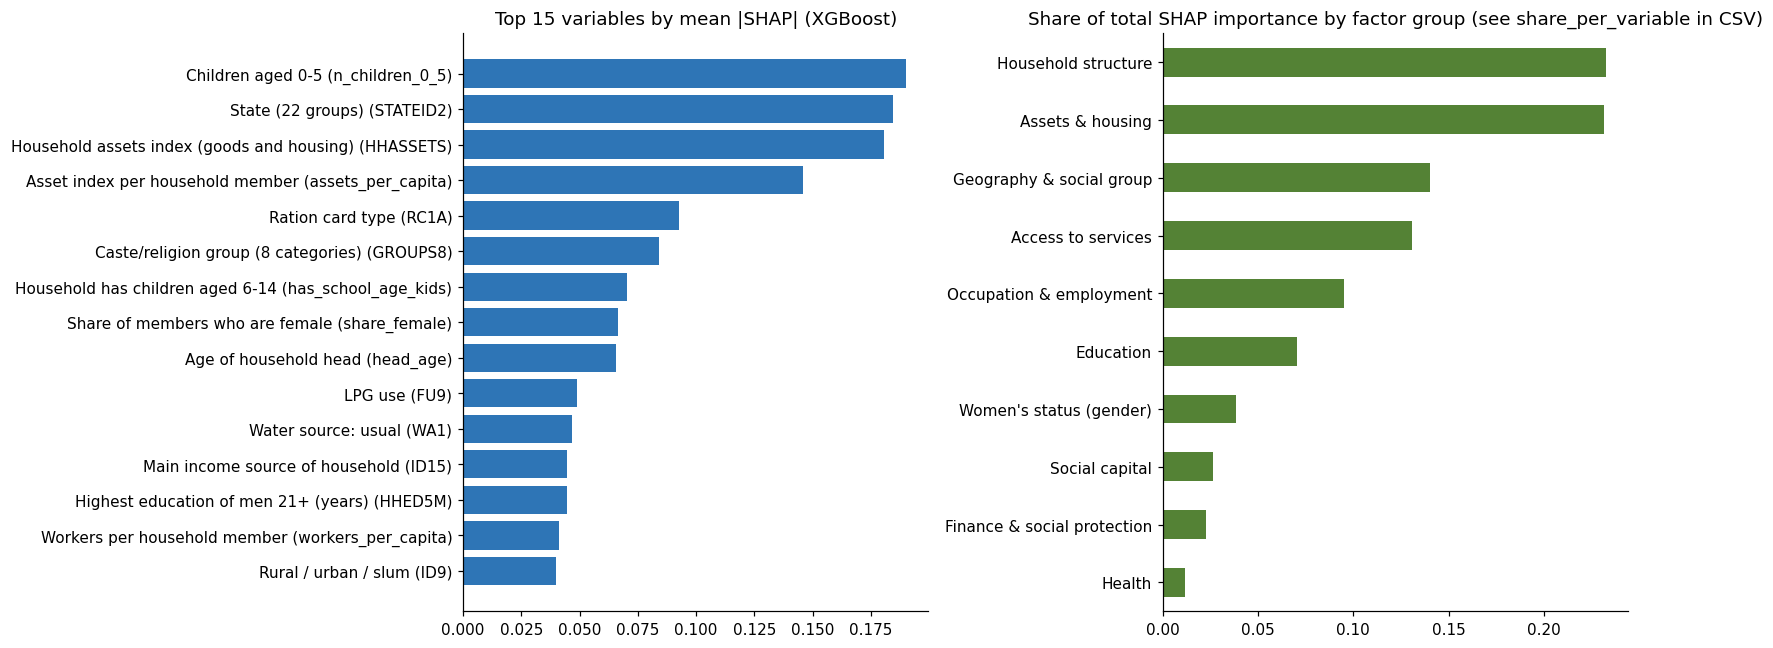

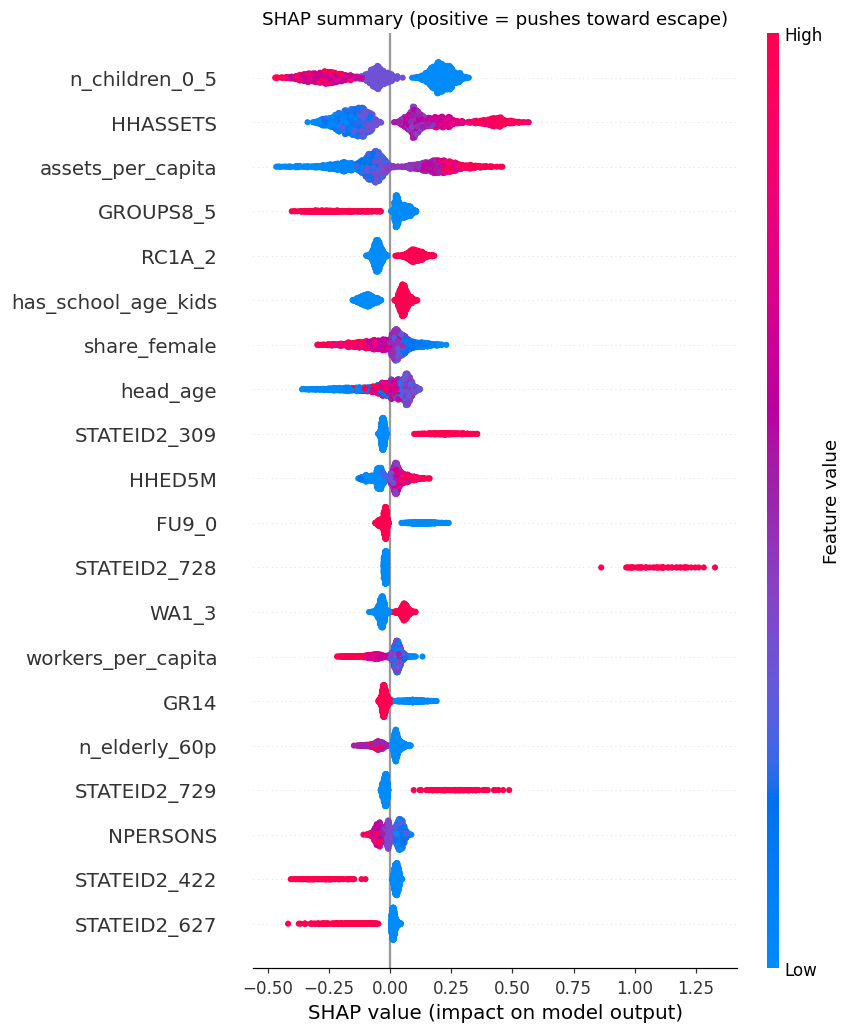

In [31]:
# The tuned XGBoost pipeline has two parts: pre-processing ("prep") and the model itself ("clf").
xgboost_model = best_models["XGBoost"]
preprocessor = xgboost_model.named_steps["prep"]
booster = xgboost_model.named_steps["clf"]

# Apply the pre-processing to the test inputs (SHAP needs the numbers the model really sees).
X_test_encoded = preprocessor.transform(X_test)
X_test_encoded = X_test_encoded.toarray() if hasattr(X_test_encoded, "toarray") else np.asarray(X_test_encoded)
encoded_names = [name.split("__", 1)[1] for name in preprocessor.get_feature_names_out()]

# SHAP values: one number per household per encoded column.
shap_values = shap.TreeExplainer(booster).shap_values(X_test_encoded)
shap_values = shap_values[1] if isinstance(shap_values, list) else shap_values


def original_variable(encoded_name):
    """Map an encoded column name back to the original survey variable.

    Example: "GROUPS8_5" (one-hot column for caste group 5) -> "GROUPS8". Numeric columns map to themselves.
    """
    for name in sorted(NOMINAL, key=len, reverse=True):
        if encoded_name == name or encoded_name.startswith(name + "_"):
            return name
    return encoded_name


# Contribution of a variable to one household = sum of the SHAP values of its one-hot columns.
# Importance of a variable = average of the absolute value of that household contribution.
shap_by_household = pd.DataFrame(shap_values, columns=encoded_names).T.groupby(original_variable).sum().T
importance_by_variable = shap_by_household.abs().mean().sort_values(ascending=False)

# Table of the 20 most important variables.
top_variables = importance_by_variable.head(20).to_frame("mean_abs_SHAP")
top_variables["label"] = [feature_info[name]["label"] for name in top_variables.index]
top_variables["group"] = [feature_info[name]["group"] for name in top_variables.index]
display(top_variables.round(4))
top_variables.to_csv(OUTPUT_DIR / "shap_top_variables.csv")

# Importance by factor group (education, assets, health, ...).
importance_by_group = importance_by_variable.groupby(lambda name: feature_info[name]["group"]).sum()
importance_by_group = importance_by_group.sort_values(ascending=False)
group_table = (importance_by_group / importance_by_group.sum()).to_frame("share_of_total_SHAP")
variables_per_group = pd.Series({name: feature_info[name]["group"] for name in FEATURES}).value_counts()
group_table["n_variables"] = variables_per_group.reindex(group_table.index)
group_table["share_per_variable"] = group_table["share_of_total_SHAP"] / group_table["n_variables"]
display(group_table.round(3))
group_table.to_csv(OUTPUT_DIR / "shap_by_group.csv")

# Chart: top 15 variables (left) and share by group (right).
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top15 = importance_by_variable.head(15)[::-1]
bar_labels = [f"{feature_info[name]['label'][:42]} ({name})" for name in top15.index]
axes[0].barh(bar_labels, top15.values, color="#2e75b6")
axes[0].set_title("Top 15 variables by mean |SHAP| (XGBoost)")
group_table["share_of_total_SHAP"][::-1].plot.barh(ax=axes[1], color="#548235")
axes[1].set_title("Share of total SHAP importance by factor group (see share_per_variable in CSV)")
save_figure("shap_importance.png")
plt.show()

# SHAP summary chart: every dot is a household; colour = size of the input value.
plt.figure()
shap.summary_plot(shap_values, pd.DataFrame(X_test_encoded, columns=encoded_names), max_display=20, show=False)
plt.title("SHAP summary (positive = pushes toward escape)")
save_figure("shap_summary.png")
plt.show()

REPORT_NUMBERS.update(shap_top10=top_variables.head(10).reset_index().rename(columns={"index": "variable"}).round(4).to_dict("records"),
                      shap_group_share=group_table["share_of_total_SHAP"].round(3).to_dict(),
                      shap_group_per_variable=group_table["share_per_variable"].round(4).to_dict())

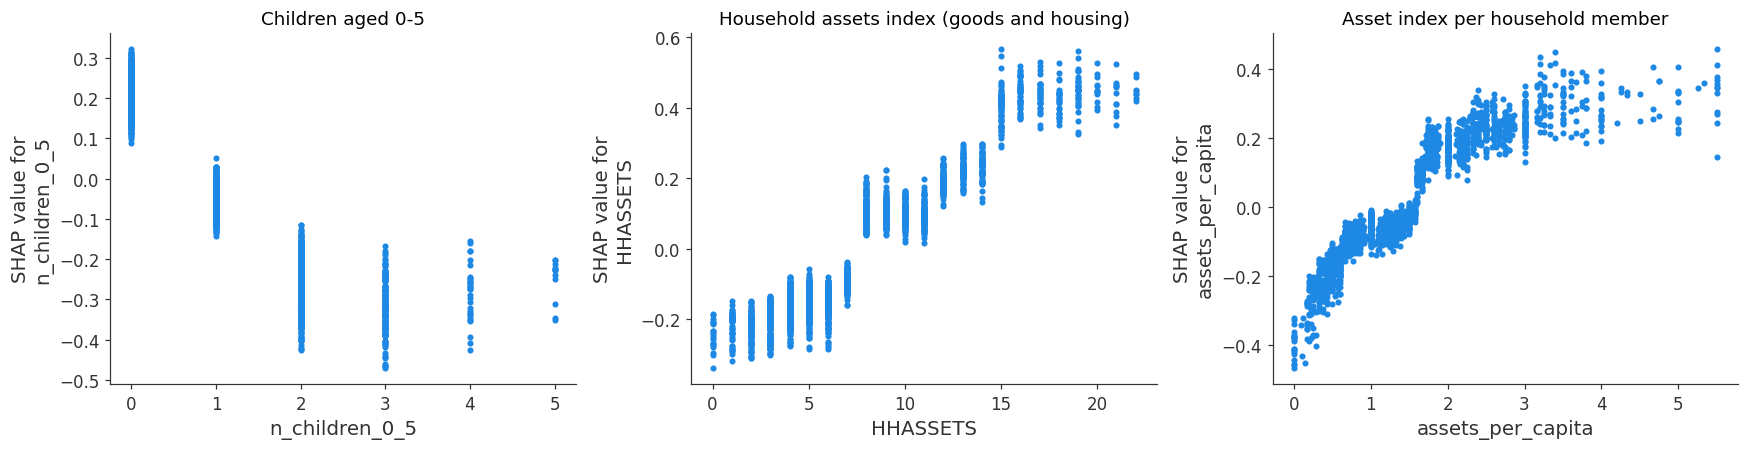

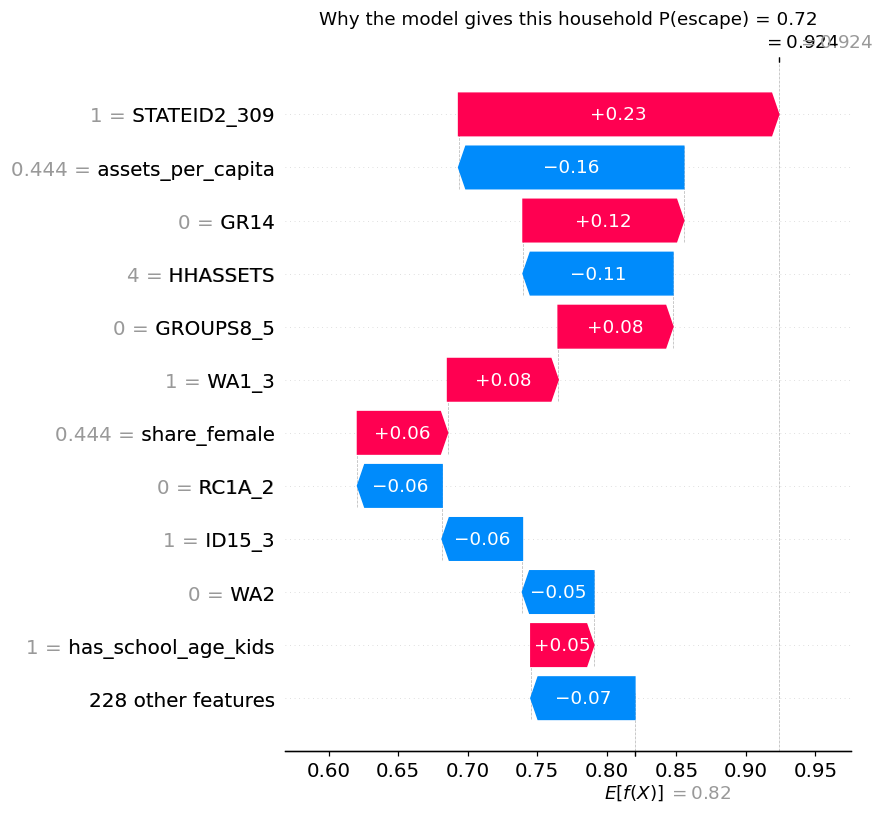

In [32]:
# Table of encoded inputs as a DataFrame (used for the dependence plots and the single-household chart).
X_test_table = pd.DataFrame(X_test_encoded, columns=encoded_names)

# Dependence plots: how the SHAP value changes with the input value, for the 3 top numeric variables.
top_numeric = [name for name in importance_by_variable.index if name in NUMERIC][:3]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for axis, name in zip(axes, top_numeric):
    shap.dependence_plot(name, shap_values, X_test_table, interaction_index=None, ax=axis, show=False)
    axis.set_title(feature_info[name]["label"][:48])
save_figure("shap_dependence.png")
plt.show()

# Pick a household in the middle of the predicted-probability range as a worked example.
xgboost_probs = test_probs["XGBoost"]
example = int(np.argsort(xgboost_probs)[len(xgboost_probs) // 2])

# Waterfall chart: how each input moves the prediction of this one household.
import xgboost as xgb
base_value = float(booster.get_booster().predict(xgb.DMatrix(X_test_encoded[:1]), pred_contribs=True)[0, -1])   # exact base value of the model
explanation = shap.Explanation(values=shap_values[example], base_values=base_value,
                               data=X_test_table.iloc[example].values, feature_names=encoded_names)
plt.figure()
shap.plots.waterfall(explanation, max_display=12, show=False)
plt.title(f"Why the model gives this household P(escape) = {xgboost_probs[example]:.2f}")
save_figure("shap_waterfall_example.png")
plt.show()

In [33]:
# Odds ratios from Logistic Regression: a second, easy-to-read view of the same question.
# An odds ratio above 1 means the input goes with a HIGHER chance of escape; below 1 means LOWER.
logistic_model = best_models["Logistic Regression"]
logistic_prep = logistic_model.named_steps["prep"]
logistic_step = logistic_model.named_steps["clf"]

# One coefficient per encoded column (numeric columns are scaled, so the odds ratio is "per 1 standard deviation").
coefficient_names = [name.split("__", 1)[1] for name in logistic_prep.get_feature_names_out()]
coefficients = pd.Series(logistic_step.coef_[0], index=coefficient_names)

# Turn coefficients into odds ratios and sort by strength (distance from 1).
odds_table = pd.DataFrame({"odds_ratio": np.exp(coefficients)})
odds_table["label"] = [feature_info[original_variable(name)]["label"] for name in odds_table.index]
odds_table["strength"] = np.abs(coefficients)
odds_table = odds_table.sort_values("strength", ascending=False).drop(columns="strength")
display(odds_table.head(15).round(3))
odds_table.head(30).to_csv(OUTPUT_DIR / "logistic_odds_ratios.csv")

,odds_ratio,label
STATEID2_728,2.746,State (22 groups)
STATEID2_517,1.822,State (22 groups)
STATEID2_422,0.596,State (22 groups)
STATEID2_624,1.592,State (22 groups)
HQ4_7,0.656,Obs: Wall type
STATEID2_206,0.657,State (22 groups)
STATEID2_102,0.662,State (22 groups)
STATEID2_729,1.488,State (22 groups)
HQ4_9,1.369,Obs: Wall type
HQ5_7,1.365,Obs: Roof type


## 10. Robustness checks

**(a) Does more information help?** We keep the tuned model settings fixed and add one block of information at a time. Each row shows 5-fold village cross-validation ROC-AUC on the training villages (average of 3 shuffled repeats) and the test ROC-AUC. The blocks are:
- the final feature set;
- **village survey** (roads, schools, clinics, distance to town; rural villages only);
- **"village-mates" context** (average assets, education, electricity, water, caste mix and household size of the *other* households in the same village);
- an **ablation that adds consumption and income** (poverty-gap ratio, log income, village poverty rate): the information we excluded on purpose.

**(b) Other ways to define "escaped" for split households.**

**(c) Attrition re-weighting.** Poor households we could not follow (Section 3) differ from those we could. We give each followed household a weight (1 / its probability of being followed) so that the followed group looks like all wave-1 poor households.

**(d) The older poverty line.** Keep only households that were *also* poor on the old wave-1 line (the deeper-poor group).

**(e) Survey weights.** IHDS recommends the weight `SWEIGHT` for population estimates. We report weighted escape rates and weighted AUC.

**(f) Repeated village splits.** One train/test split gives one number. We repeat the train/test step on 20 different village splits to see how much the scores and the ranking of the models move. The tuned settings are kept fixed from Section 7, so about 80% of each new test set was part of the original training set: read this check as the *stability of the ranking*, not as unbiased scores. The 20 test sets overlap, so the 20 results are not independent trials.

**(g) Without the ration card.** The ration card type is a government poverty label. We refit Logistic Regression and XGBoost (same settings) without it.

In [34]:
# Row numbers of `data` must be 0, 1, 2, ... so extra tables can be attached by position.
assert (data.index == np.arange(len(data))).all()

# ---- Block 1: village survey (rural villages only) ----
household_keys = data[["IDHH"]].merge(wave1[["IDHH", "STATEID", "DISTID", "PSUID"]], on="IDHH", how="left")
VILLAGE_COLUMNS = ["VI1B", "VI2B", "VI3A", "VI3B", "VI3C", "VI4A", "VI7", "VI11A", "VI11B", "VI13B", "VI13C",
                   "VI13E", "VSA2", "VSA3", "VSA4", "VMA1", "VMA2", "VMD1", "VI14D", "VI15A", "VI15B",
                   "VE5C", "VE6C", "TOTHH"]
villages, _ = read_survey_file(DATA_PATHS["22626-0007-Data.dta"], ["STATEID", "DISTID", "PSUID"] + VILLAGE_COLUMNS)
village_block = household_keys.merge(villages, on=["STATEID", "DISTID", "PSUID"], how="left")[VILLAGE_COLUMNS]
print(f"Village survey attached for {village_block['VI1B'].notna().mean():.1%} of households "
      "(rural villages only; urban neighbourhoods have no village record)")


def leave_one_out_mean(table, column, group_column="IDPSU"):
    """Average of a column over the OTHER households of the same village.

    The household's own value is left out, so the feature describes its neighbours, not itself.

    Input : table        - table with one row per household.
            column       - column to average.
            group_column - column that identifies the village (default IDPSU).
    Output: one number per household (empty if the household has no neighbours with a value).
    """
    values = table[column]
    has_value = values.notna()
    village_sum = values.where(has_value).groupby(table[group_column]).transform("sum")
    village_count = has_value.groupby(table[group_column]).transform("sum")
    neighbour_count = village_count - has_value.astype(int)
    neighbour_sum = village_sum - values.where(has_value, 0)
    return neighbour_sum / neighbour_count.where(neighbour_count > 0)


# ---- Block 2: "village-mates" context (averages over the other households in the same village) ----
context_source = features_all.merge(wave1[["IDHH", "POOR"]], on="IDHH", how="left")
context_source["dalit_adivasi"] = context_source["GROUPS8"].isin([4, 5]).astype(float)
context_source["poor05"] = (context_source["POOR"] == 1).astype(float).where(context_source["POOR"].isin([0, 1]))

context_variables = [("HHASSETS", "ctx_assets"), ("HHED5ADULT", "ctx_educ"), ("FU1", "ctx_electric"),
                     ("WA2", "ctx_water_in_house"), ("dalit_adivasi", "ctx_dalit_adivasi"), ("NPERSONS", "ctx_hhsize")]
context_all = pd.DataFrame({"IDHH": context_source["IDHH"]})
for source_column, new_name in context_variables:
    context_all[new_name] = leave_one_out_mean(context_source, source_column).values
context_all["ctx_poor05"] = leave_one_out_mean(context_source, "poor05").values
context_block = data[["IDHH"]].merge(context_all, on="IDHH", how="left").drop(columns="IDHH")

# ---- Block 3 (ablation): consumption and income, the information we left out on purpose ----
spending = data[["IDHH"]].merge(wave1[["IDHH", "COPC", "LINE05", "INCOME"]], on="IDHH", how="left")
gap_block = pd.DataFrame({"poverty_gap_ratio": (spending["COPC"] / spending["LINE05"]).values,
                          "log_income": np.log1p(spending["INCOME"].clip(lower=0)).values})

Village survey attached for 75.6% of households (rural villages only; urban neighbourhoods have no village record)


In [35]:
def compare_feature_set(label, extra_blocks):
    """Test one feature set with the already-tuned model settings.

    For Logistic Regression and XGBoost it reports:
      - CV AUC : ROC-AUC from 5-fold village cross-validation on the training villages, averaged over 3 shuffles;
      - test AUC: ROC-AUC on the held-out test villages after fitting on all training data.

    Input : label        - name of the feature set shown in the table.
            extra_blocks - list of extra tables (same row order as `data`) added to the final features.
    Output: dictionary with one row of results.
    """
    X_extended = pd.concat([X] + list(extra_blocks), axis=1)
    extra_columns = [column for block in extra_blocks for column in block.columns]
    row = {"Feature set": label, "n_features": len(NUMERIC) + len(NOMINAL) + len(extra_columns)}

    for short_name, model_name in [("LR", "Logistic Regression"), ("XGB", "XGBoost")]:
        # Same tuned settings, but the pre-processing must know about the extra numeric columns.
        model = clone(best_models[model_name])
        model.set_params(prep=make_preprocessor(scale=(model_name == "Logistic Regression"),
                                                numeric_columns=NUMERIC + extra_columns))

        # Cross-validation, repeated with 3 different shuffles of the villages.
        cv_scores = []
        for shuffle_seed in (0, 1, 2):
            folds = stable_group_folds(groups_train, n_splits=5, seed=shuffle_seed)
            probabilities = cross_val_predict(clone(model), X_extended.iloc[train_idx], y_train,
                                              method="predict_proba", n_jobs=-1, cv=folds)[:, 1]
            cv_scores.append(roc_auc_score(y_train, probabilities))
        row[f"{short_name} CV AUC"] = np.mean(cv_scores)

        # Fit on all training data and score on the test villages.
        fitted_model = clone(model).fit(X_extended.iloc[train_idx], y_train)
        test_probabilities = fitted_model.predict_proba(X_extended.iloc[test_idx])[:, 1]
        row[f"{short_name} test AUC"] = roc_auc_score(y_test, test_probabilities)
    return row


# One row per feature set.
feature_set_rows = [
    compare_feature_set("Final feature set (structural, no consumption/income)", []),
    compare_feature_set("+ village-survey infrastructure (rural only)", [village_block]),
    compare_feature_set("+ village-mates context (leave-one-out)", [context_block.drop(columns="ctx_poor05")]),
    compare_feature_set("ABLATION: + consumption gap, income, village poverty rate", [gap_block, context_block[["ctx_poor05"]]]),
]
feature_set_table = pd.DataFrame(feature_set_rows).set_index("Feature set")
display(feature_set_table.round(4))
feature_set_table.round(4).to_csv(OUTPUT_DIR / "feature_set_comparison.csv")
REPORT_NUMBERS["feature_sets"] = feature_set_table.round(4).reset_index().to_dict("records")

# How strong is the baseline poverty gap on its own (without any other feature)?
gap_ratio = gap_block["poverty_gap_ratio"]
gap_auc = roc_auc_score(y, gap_ratio.fillna(gap_ratio.median()))
gap_quintile = pd.qcut(gap_ratio, 5, labels=False, duplicates="drop")
escape_by_gap = pd.Series(y).groupby(gap_quintile.values).mean()
print(f"ROC-AUC of the wave-1 poverty-gap ratio ALONE: {gap_auc:.3f} | "
      f"escape rate by gap quintile (deepest to shallowest poverty): {escape_by_gap.round(3).tolist()}")
REPORT_NUMBERS["gap_alone_auc"] = float(gap_auc)

,n_features,LR CV AUC,LR test AUC,XGB CV AUC,XGB test AUC
Feature set,,,,,
"Final feature set (structural, no consumption/income)",137,0.6880,0.6998,0.6966,0.7220
+ village-survey infrastructure (rural only),161,0.6865,0.6988,0.6939,0.7223
+ village-mates context (leave-one-out),143,0.6866,0.6996,0.6924,0.7161
"ABLATION: + consumption gap, income, village poverty rate",140,0.6928,0.7002,0.7003,0.7187


ROC-AUC of the wave-1 poverty-gap ratio ALONE: 0.602 | escape rate by gap quintile (deepest to shallowest poverty): [0.557, 0.664, 0.734, 0.747, 0.767]


In [36]:
# ---- (b) Other rules for "escaped" when the household split into several households ----
split_info = data[["IDHH"]].merge(poor_wave1[["IDHH", "poor_mean", "n_w2"]], on="IDHH", how="left")

# Row 1 is the main rule, scored with the XGBoost model already trained.
rule_rows = [{"Target rule": "Primary: continuing household (HHSPLITID=1)", "n": len(data),
              "Escape rate": y.mean(), "ROC_AUC (test)": roc_auc_score(y_test, test_probs["XGBoost"])}]

# The two alternative rules: escaped only if ALL descendants are not poor, or if ANY descendant is not poor.
alternative_rules = [("Escaped only if ALL descendant households non-poor", split_info.poor_mean == 0),
                     ("Escaped if ANY descendant household non-poor", split_info.poor_mean < 1)]
has_outcome = split_info.poor_mean.notna().to_numpy()

for rule_label, alt_target in alternative_rules:
    alt_target = alt_target.to_numpy().astype(int)

    # Keep only households with a known outcome under this rule.
    train_rows = train_idx[has_outcome[train_idx]]
    test_rows = test_idx[has_outcome[test_idx]]

    # Re-fit XGBoost (same tuned settings) on the alternative target.
    model = clone(best_models["XGBoost"])
    model.fit(X.iloc[train_rows], alt_target[train_rows])

    auc = roc_auc_score(alt_target[test_rows], model.predict_proba(X.iloc[test_rows])[:, 1])
    rule_rows.append({"Target rule": rule_label, "n": int(has_outcome.sum()),
                      "Escape rate": alt_target[has_outcome].mean(), "ROC_AUC (test)": auc})

rule_table = pd.DataFrame(rule_rows)
display(rule_table.round(4))
rule_table.round(4).to_csv(OUTPUT_DIR / "sensitivity_target_rules.csv")
REPORT_NUMBERS["sensitivity"] = rule_table.round(4).to_dict("records")

,Target rule,n,Escape rate,ROC_AUC (test)
0,Primary: continuing household (HHSPLITID=1),11146,0.6936,0.7220
1,Escaped only if ALL descendant households non-...,11146,0.6660,0.7271
2,Escaped if ANY descendant household non-poor,11146,0.7163,0.7205


In [37]:
# ---- (c) Weights that correct for households we could not follow (attrition) ----
# Features of ALL wave-1 poor households (kept and lost), in the same format as the model inputs.
attrition_X = poor_wave1[["IDHH", "IDPSU", "kept"]].merge(features_all.drop(columns=["IDPSU"]), on="IDHH", how="left")
attrition_inputs = attrition_X[FEATURES].copy()
for name in NOMINAL:
    attrition_inputs[name] = codes_to_text(attrition_inputs[name])

# Model for "was this household followed up?": predictions come from cross-validation by village.
follow_model = Pipeline([("prep", make_preprocessor(scale=True)),
                         ("clf", LogisticRegression(max_iter=3000, C=0.05))])
prob_followed = cross_val_predict(follow_model, attrition_inputs, attrition_X["kept"].astype(int),
                                  cv=stable_group_folds(attrition_X["IDPSU"].to_numpy(), n_splits=5),
                                  method="predict_proba", n_jobs=-1)[:, 1]

# Weight = 1 / probability of being followed; cap the most extreme 1% on each side.
weights_all = pd.Series(1.0 / prob_followed, index=attrition_X["IDHH"])
weights_all = weights_all.clip(*weights_all.quantile([0.01, 0.99]))

# Weights of the households in our modelling table (same order as `data`).
weights_table = weights_all.rename("w").reset_index()
weights = data[["IDHH"]].merge(weights_table, on="IDHH", how="left")["w"].to_numpy()

# Re-train XGBoost with these weights and score both versions with the weights.
weighted_model = clone(best_models["XGBoost"]).fit(X_train, y_train, clf__sample_weight=weights[train_idx])
weighted_probs = weighted_model.predict_proba(X_test)[:, 1]
ipw_table = pd.DataFrame(
    {"Escape rate": [y.mean(), np.average(y, weights=weights)],
     "XGBoost test AUC (IPW-weighted evaluation)": [
         roc_auc_score(y_test, test_probs["XGBoost"], sample_weight=weights[test_idx]),
         roc_auc_score(y_test, weighted_probs, sample_weight=weights[test_idx])]},
    index=["Unweighted model / raw sample", "IPW-weighted model / re-weighted sample"])
display(ipw_table.round(4))
ipw_table.round(4).to_csv(OUTPUT_DIR / "attrition_ipw.csv")
print(f"Probability of being followed ranges {prob_followed.min():.2f}-{prob_followed.max():.2f}; "
      f"capped weights {weights.min():.2f}-{weights.max():.2f}")

REPORT_NUMBERS["ipw"] = {"escape_rate_raw": float(y.mean()), "escape_rate_ipw": float(np.average(y, weights=weights)),
                         "auc_raw": float(ipw_table.iloc[0, 1]), "auc_ipw": float(ipw_table.iloc[1, 1])}

,Escape rate,XGBoost test AUC (IPW-weighted evaluation)
Unweighted model / raw sample,0.6936,0.7237
IPW-weighted model / re-weighted sample,0.6975,0.7187


Probability of being followed ranges 0.12-1.00; capped weights 1.01-2.25


In [38]:
# ---- (d) Only households that were ALSO poor on the old wave-1 line (the deeper-poor group) ----
old_flag = data[["IDHH"]].merge(wave1[["IDHH", "POOR_OLD"]], on="IDHH", how="left")["POOR_OLD"].to_numpy()
deeper = old_flag == 1
deeper_train = train_idx[deeper[train_idx]]
deeper_test = test_idx[deeper[test_idx]]

old_line_rows = []
for model_name in ["Logistic Regression", "XGBoost"]:
    # (i) the main model (trained on all poor households) scored only on deeper-poor test households
    main_auc = roc_auc_score(y[deeper_test], test_probs[model_name][np.isin(test_idx, deeper_test)])
    # (ii) the same settings refitted on deeper-poor training households only
    refit = clone(best_models[model_name]).fit(X.iloc[deeper_train], y[deeper_train])
    refit_auc = roc_auc_score(y[deeper_test], refit.predict_proba(X.iloc[deeper_test])[:, 1])
    old_line_rows.append({"Model": model_name, "households (deeper poor)": int(deeper.sum()),
                          "escape rate (deeper poor)": float(y[deeper].mean()),
                          "AUC: main model": main_auc, "AUC: refitted on deeper poor": refit_auc})
old_line_table = pd.DataFrame(old_line_rows).set_index("Model")
display(old_line_table.round(4))
old_line_table.round(4).to_csv(OUTPUT_DIR / "sensitivity_old_line.csv")
REPORT_NUMBERS["old_line"] = old_line_table.round(4).reset_index().to_dict("records")


,households (deeper poor),escape rate (deeper poor),AUC: main model,AUC: refitted on deeper poor
Model,,,,
Logistic Regression,7080,0.6569,0.6953,0.6848
XGBoost,7080,0.6569,0.7140,0.6966


In [39]:
# ---- (e) Survey weights (SWEIGHT = design weight recommended by the IHDS guides) ----
survey_weight = data[["IDHH"]].merge(wave1[["IDHH", "SWEIGHT"]], on="IDHH", how="left")["SWEIGHT"].to_numpy()
weight_rows = [{"Model": name,
                "AUC unweighted": roc_auc_score(y_test, test_probs[name]),
                "AUC weighted": roc_auc_score(y_test, test_probs[name], sample_weight=survey_weight[test_idx])}
               for name in test_probs if not name.startswith("Dummy")]
weight_table = pd.DataFrame(weight_rows).set_index("Model")
display(weight_table.round(4))
weight_table.round(4).to_csv(OUTPUT_DIR / "sensitivity_survey_weights.csv")
effective_n = survey_weight.sum() ** 2 / (survey_weight ** 2).sum()
print(f"Escape rate: unweighted {y.mean():.1%} | weighted by SWEIGHT {np.average(y, weights=survey_weight):.1%} | "
      f"effective sample size {effective_n:,.0f} of {len(y):,}")
REPORT_NUMBERS["survey_weights"] = {"escape_rate_unweighted": float(y.mean()),
                                    "escape_rate_weighted": float(np.average(y, weights=survey_weight)),
                                    "effective_n": float(effective_n),
                                    "auc": weight_table.round(4).reset_index().to_dict("records")}


,AUC unweighted,AUC weighted
Model,,
Logistic Regression,0.6998,0.6681
Random Forest,0.7087,0.6893
XGBoost,0.7220,0.7012
Soft-vote ensemble (LR+RF+XGB),0.7187,0.6946


Escape rate: unweighted 69.4% | weighted by SWEIGHT 68.2% | effective sample size 5,581 of 11,146


In [40]:
# ---- (f) Repeated village splits: how much do scores and rankings move from split to split? ----
N_SPLITS = 20
split_rows = []
for split_number in range(N_SPLITS):
    splitter_k = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1000 + split_number)
    train_k, test_k = next(splitter_k.split(X, y, groups))
    probs_k = {}
    for model_name in ["Logistic Regression", "Random Forest", "XGBoost"]:
        model_k = clone(best_models[model_name])
        if model_name == "Random Forest":
            model_k.set_params(clf__n_jobs=-1)
        probs_k[model_name] = model_k.fit(X.iloc[train_k], y[train_k]).predict_proba(X.iloc[test_k])[:, 1]
    probs_k[ENSEMBLE] = np.mean([probs_k[name] for name in ["Logistic Regression", "Random Forest", "XGBoost"]], axis=0)
    split_rows.append({name: roc_auc_score(y[test_k], probs_k[name]) for name in probs_k})
split_table = pd.DataFrame(split_rows)
split_summary = split_table.agg(["mean", "std", "min", "max"]).T
split_summary["best_in_n_splits"] = split_table.idxmax(axis=1).value_counts().reindex(split_summary.index).fillna(0).astype(int)
display(split_summary.round(4))
split_table.round(4).to_csv(OUTPUT_DIR / "repeated_split_auc.csv", index=False)
print("Mean paired difference (ensemble - Logistic Regression):",
      round((split_table[ENSEMBLE] - split_table["Logistic Regression"]).mean(), 4),
      "| (ensemble - XGBoost):", round((split_table[ENSEMBLE] - split_table["XGBoost"]).mean(), 4),
      "| (ensemble - Random Forest):", round((split_table[ENSEMBLE] - split_table["Random Forest"]).mean(), 4))
REPORT_NUMBERS["repeated_splits"] = split_summary.round(4).reset_index().rename(columns={"index": "Model"}).to_dict("records")


,mean,std,min,max,best_in_n_splits
Logistic Regression,0.7007,0.0136,0.6787,0.7331,0
Random Forest,0.6957,0.0163,0.6666,0.7243,0
XGBoost,0.7096,0.0148,0.6821,0.7374,5
Soft-vote ensemble (LR+RF+XGB),0.7108,0.0150,0.6853,0.7414,15


Mean paired difference (ensemble - Logistic Regression): 0.0101 | (ensemble - XGBoost): 0.0013 | (ensemble - Random Forest): 0.0151


In [41]:
# ---- (g) Without the ration card variables (a government poverty label) ----
ration_columns = ["RC1", "RC1A"]
numeric_without = [name for name in NUMERIC if name not in ration_columns]
nominal_without = [name for name in NOMINAL if name not in ration_columns]


def preprocessor_without_ration(scale):
    """Same pre-processing as make_preprocessor, but without the ration card columns."""
    numeric_steps = [("clip", ClipOutliers()), ("fill", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    one_hot = OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False)
    return ColumnTransformer([("num", Pipeline(numeric_steps), numeric_without), ("cat", one_hot, nominal_without)])


ration_rows = []
for model_name in ["Logistic Regression", "XGBoost"]:
    refit_model = clone(best_models[model_name]).set_params(prep=preprocessor_without_ration(model_name == "Logistic Regression"))
    refit_model.fit(X_train, y_train)
    ration_rows.append({"Model": model_name, "AUC with ration card": roc_auc_score(y_test, test_probs[model_name]),
                        "AUC without ration card": roc_auc_score(y_test, refit_model.predict_proba(X_test)[:, 1])})
ration_table = pd.DataFrame(ration_rows).set_index("Model")
display(ration_table.round(4))
ration_table.round(4).to_csv(OUTPUT_DIR / "sensitivity_ration_card.csv")
REPORT_NUMBERS["ration_card"] = ration_table.round(4).reset_index().to_dict("records")


,AUC with ration card,AUC without ration card
Model,,
Logistic Regression,0.6998,0.6964
XGBoost,0.7220,0.7148


### Why split by village? (check)

If we split households at random instead, neighbours from the same village end up in both the training and the test part.
We repeat both kinds of split 20 times with the same XGBoost settings and compare the average scores.


In [42]:
# ---- Why split by village? Compare with an ordinary random split of households ----
from sklearn.model_selection import train_test_split

random_split_aucs = []
for repeat in range(20):
    train_r, test_r = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=2000 + repeat)
    model_r = clone(best_models["XGBoost"]).fit(X.iloc[train_r], y[train_r])
    random_split_aucs.append(roc_auc_score(y[test_r], model_r.predict_proba(X.iloc[test_r])[:, 1]))
village_split_aucs = split_table["XGBoost"]          # the 20 village splits of check (f), same model and settings
print(f"XGBoost ROC-AUC with an ordinary random split : mean {np.mean(random_split_aucs):.3f} (sd {np.std(random_split_aucs, ddof=1):.3f}, 20 splits)")
print(f"XGBoost ROC-AUC with a split by village        : mean {village_split_aucs.mean():.3f} (sd {village_split_aucs.std():.3f}, 20 splits)")
print("A random split lets neighbours from the same village sit in both parts, so it can only look the same or better than the village split.")
REPORT_NUMBERS["random_vs_village"] = {"random_mean": float(np.mean(random_split_aucs)), "random_sd": float(np.std(random_split_aucs, ddof=1)),
                                       "village_mean": float(village_split_aucs.mean()), "village_sd": float(village_split_aucs.std())}


XGBoost ROC-AUC with an ordinary random split : mean 0.708 (sd 0.009, 20 splits)
XGBoost ROC-AUC with a split by village        : mean 0.710 (sd 0.015, 20 splits)
A random split lets neighbours from the same village sit in both parts, so it can only look the same or better than the village split.


## 11. Extension: is education linked to escape? (estimators with valid confidence intervals)

Prediction and SHAP show **association**. To get closer to cause and effect we ask a narrower question:

> Among poor households, do those whose most-educated adult finished secondary school (10+ years) escape more often than *similar* households whose most-educated adult did not?

**How it works (plain English)**
1. *Treated* households: highest adult education is 10 years or more. *Control* households: less.
2. We compare them after adjusting for starting characteristics (state, caste, religion, urban/rural, household size, head's age and sex, land, dependency ratio). Three ways of adjusting are reported, so the answer does not depend on one method:
   - **Regression adjustment:** fit a model for escape among controls, and predict what treated households would have done without the education.
   - **Inverse-probability weighting (IPW):** give controls a weight so that they look like the treated group (weight = chance of being treated / chance of not).
   - **Doubly robust (AIPW):** combines both; it is right if *either* model is right.
3. The effect is the **ATT**: the difference in escape rate for the treated households. Confidence intervals come from a **village bootstrap** (re-draw whole villages and redo everything), which is valid for these smooth estimators.
4. A second set of results also adjusts for the household's **baseline depth of poverty** (spending per person divided by the poverty line, in 2004-05). It is measured before the outcome, but at the same time as education and it may itself be partly a result of education, so this version may over-adjust. Together the two versions give a plausible range.
5. A nearest-neighbour matching estimate is shown for comparison (point estimate only: the ordinary bootstrap is not valid for matching with replacement).
6. The **E-value** says how strong a hidden factor would have to be to explain the result away.

We do **not** use assets, occupation or services as adjustment variables, because education may have influenced them. This is a *checked association*, not proof of cause. All results are for households that were already poor in 2004-05, so they say nothing about how education affects the chance of being poor in the first place.

In [43]:
def match_households(covariates, treated, caliper_sd=0.2):
    """Match every treated household to the most similar control household (propensity score matching).

    Steps: (1) estimate each household's chance of being treated from its covariates;
           (2) convert it to log-odds; (3) for each treated household find the control with the
           closest log-odds (controls can be used more than once);
           (4) drop matches that are too far apart (farther than `caliper_sd` x the spread of log-odds).

    Input : covariates - table of baseline characteristics (numbers only).
            treated    - array of 0/1, 1 = treated household.
            caliper_sd - largest allowed distance, in standard deviations of the log-odds.
    Output: (treated rows, matched control rows, propensity scores, share of treated households matched).
    """
    scaled = StandardScaler().fit_transform(covariates)
    scores = LogisticRegression(max_iter=2000, C=1.0).fit(scaled, treated).predict_proba(scaled)[:, 1]
    scores = scores.clip(1e-4, 1 - 1e-4)
    log_odds = np.log(scores / (1 - scores))
    max_distance = caliper_sd * log_odds.std()

    treated_rows = np.where(treated == 1)[0]
    control_rows = np.where(treated == 0)[0]
    finder = NearestNeighbors(n_neighbors=1).fit(log_odds[control_rows].reshape(-1, 1))
    distance, nearest = finder.kneighbors(log_odds[treated_rows].reshape(-1, 1))

    close_enough = distance[:, 0] <= max_distance
    return treated_rows[close_enough], control_rows[nearest[close_enough, 0]], scores, close_enough.mean()


def att_estimates(covariates, treated, outcome):
    """Estimate the average effect on the treated (ATT) in three ways.

    Input : covariates - 2-D array of baseline characteristics (already scaled);
            treated    - array of 0/1; outcome - array of 0/1 (1 = escaped).
    Output: dictionary with the raw difference, regression adjustment, IPW and doubly robust (AIPW) estimates,
            plus the propensity scores. All are differences in escape rate (percentage points / 100).
    """
    propensity = LogisticRegression(max_iter=2000, C=1.0).fit(covariates, treated).predict_proba(covariates)[:, 1]
    propensity = propensity.clip(0.01, 0.99)
    control_model = LogisticRegression(max_iter=2000, C=1.0).fit(covariates[treated == 0], outcome[treated == 0])
    predicted_without = control_model.predict_proba(covariates)[:, 1]          # what each household would do untreated
    is_treated = treated == 1
    odds_weight = propensity / (1 - propensity)
    control_weight = odds_weight[~is_treated]
    treated_rate = outcome[is_treated].mean()
    raw = treated_rate - outcome[~is_treated].mean()
    regression = treated_rate - predicted_without[is_treated].mean()
    ipw = treated_rate - np.average(outcome[~is_treated], weights=control_weight)
    residual = outcome - predicted_without
    doubly_robust = residual[is_treated].mean() - np.average(residual[~is_treated], weights=control_weight)
    return {"raw": raw, "regression": regression, "ipw": ipw, "doubly_robust": doubly_robust,
            "treated_rate": treated_rate, "propensity": propensity}


def e_value(risk_ratio):
    """E-value (VanderWeele and Ding, 2017) for a risk ratio: the minimum strength of a hidden factor
    (risk ratio with both treatment and outcome) that could explain the result away. 1 means no protection."""
    risk_ratio = max(risk_ratio, 1e-9)
    risk_ratio = risk_ratio if risk_ratio >= 1 else 1 / risk_ratio
    return float(risk_ratio + np.sqrt(risk_ratio * (risk_ratio - 1)))


# Treatment: highest adult education of 10 years or more (empty if unknown).
treatment = (data["HHED5ADULT"] >= 10).astype(float).where(data["HHED5ADULT"].notna())

# Baseline characteristics that education is unlikely to have caused.
numeric_covariates = ["URBAN", "NPERSONS", "NCHILD", "NADULTS", "head_age", "head_female", "FM3", "dep_ratio"]
category_covariates = ["STATEID2", "GROUPS8", "ID14"]
category_dummies = pd.get_dummies(data[category_covariates].astype("Int64").astype(str), drop_first=True).astype(float)
covariate_table = pd.concat([data[numeric_covariates].astype(float), category_dummies], axis=1)

# Baseline depth of poverty (2004-05): log of spending per person divided by the poverty line.
baseline_gap = data[["IDHH"]].merge(wave1[["IDHH", "COPC", "LINE05"]], on="IDHH", how="left")
covariate_table_gap = covariate_table.assign(log_poverty_gap=np.log(baseline_gap["COPC"] / baseline_gap["LINE05"]).values)

known = treatment.notna().to_numpy()
treated_flag = treatment[known].astype(int).to_numpy()
outcome = y[known]
village_ids = groups[known]
print(f"Treated (adult with 10+ years of schooling): {treated_flag.sum():,} ({treated_flag.mean():.1%}) | "
      f"controls: {(1 - treated_flag).sum():,} | escape rate treated {outcome[treated_flag == 1].mean():.1%}, "
      f"controls {outcome[treated_flag == 0].mean():.1%}")

all_villages = np.unique(village_ids)
rows_by_village = {village: np.where(village_ids == village)[0] for village in all_villages}
education_results = {}
for spec_name, table in [("A: baseline characteristics", covariate_table), ("B: A + baseline poverty gap", covariate_table_gap)]:
    covariates = table[known].reset_index(drop=True)
    covariates = covariates.fillna(covariates.median())
    scaled_covariates = StandardScaler().fit_transform(covariates)

    # Point estimates on the full sample.
    estimates = att_estimates(scaled_covariates, treated_flag, outcome)

    # Village bootstrap (300 re-draws of whole villages) for the three adjusted estimators.
    rng = np.random.RandomState(SEED)
    boot = {"raw": [], "regression": [], "ipw": [], "doubly_robust": []}
    for _ in range(300):
        sample = draw_village_bootstrap_sample(rows_by_village, all_villages, rng)
        if treated_flag[sample].sum() < 30 or (1 - treated_flag[sample]).sum() < 30:
            continue
        boot_scaled = StandardScaler().fit_transform(covariates.iloc[sample].reset_index(drop=True))
        result = att_estimates(boot_scaled, treated_flag[sample], outcome[sample])
        for key in boot:
            boot[key].append(result[key])
    spec_result = {}
    for key in boot:
        low, high = np.percentile(boot[key], [2.5, 97.5])
        spec_result[key] = {"estimate": float(estimates[key]), "ci_low": float(low), "ci_high": float(high)}

    # Matching (point estimate only), and balance after weighting.
    treated_rows, control_rows, propensity_match, matched_share = match_households(covariates, treated_flag)
    spec_result["matching"] = {"estimate": float(outcome[treated_rows].mean() - outcome[control_rows].mean()),
                               "matched_share": float(matched_share)}
    propensity = estimates["propensity"]
    weights = np.where(treated_flag == 1, 1.0, propensity / (1 - propensity))
    smd_before, smd_after = [], []
    for column in covariates.columns:
        values = covariates[column].to_numpy()
        pooled_sd = np.sqrt((values[treated_flag == 1].var() + values[treated_flag == 0].var()) / 2)
        if pooled_sd == 0:
            continue
        smd_before.append((values[treated_flag == 1].mean() - values[treated_flag == 0].mean()) / pooled_sd)
        weighted_control_mean = np.average(values[treated_flag == 0], weights=weights[treated_flag == 0])
        smd_after.append((values[treated_flag == 1].mean() - weighted_control_mean) / pooled_sd)
    spec_result["max_smd_before"] = float(np.max(np.abs(smd_before)))
    spec_result["max_smd_after_ipw"] = float(np.max(np.abs(smd_after)))

    # E-value: risk ratio = treated escape rate / what treated households would have had without the education.
    treated_rate = float(estimates["treated_rate"])
    for key in ["doubly_robust"]:
        att = spec_result[key]["estimate"]
        risk_ratio = treated_rate / (treated_rate - att)
        lower_att = spec_result[key]["ci_low"]
        spec_result[key]["risk_ratio"] = float(risk_ratio)
        spec_result[key]["e_value"] = e_value(risk_ratio)
        spec_result[key]["e_value_ci_limit"] = e_value(treated_rate / (treated_rate - lower_att)) if lower_att > 0 else 1.0
    spec_result["propensity"] = propensity
    education_results[spec_name] = spec_result

    print(f"\nSpecification {spec_name}")
    for key, label in [("raw", "raw difference"), ("regression", "regression adjustment"), ("ipw", "IPW"),
                       ("doubly_robust", "doubly robust (AIPW)")]:
        r = spec_result[key]
        print(f"  {label:24s} ATT = {r['estimate'] * 100:+5.1f} points   95% village-bootstrap interval "
              f"[{r['ci_low'] * 100:+5.1f}, {r['ci_high'] * 100:+5.1f}]")
    print(f"  nearest-neighbour matching ATT = {spec_result['matching']['estimate'] * 100:+5.1f} points (point estimate only; "
          f"{spec_result['matching']['matched_share']:.1%} of treated households matched)")
    dr = spec_result["doubly_robust"]
    print(f"  Balance: largest |standardised difference| {spec_result['max_smd_before']:.2f} before, "
          f"{spec_result['max_smd_after_ipw']:.2f} after IPW weighting")
    print(f"  E-value for the doubly robust estimate: {dr['e_value']:.2f} (risk ratio {dr['risk_ratio']:.2f}); "
          f"for the confidence limit nearest 1: {dr['e_value_ci_limit']:.2f}")


Treated (adult with 10+ years of schooling): 2,205 (19.8%) | controls: 8,927 | escape rate treated 78.2%, controls 67.2%



Specification A: baseline characteristics
  raw difference           ATT = +11.1 points   95% village-bootstrap interval [ +8.7, +13.0]
  regression adjustment    ATT =  +6.4 points   95% village-bootstrap interval [ +4.1,  +8.3]
  IPW                      ATT =  +6.4 points   95% village-bootstrap interval [ +3.7,  +8.7]
  doubly robust (AIPW)     ATT =  +6.3 points   95% village-bootstrap interval [ +3.9,  +8.7]
  nearest-neighbour matching ATT =  +8.1 points (point estimate only; 99.7% of treated households matched)
  Balance: largest |standardised difference| 0.78 before, 0.12 after IPW weighting
  E-value for the doubly robust estimate: 1.40 (risk ratio 1.09); for the confidence limit nearest 1: 1.29



Specification B: A + baseline poverty gap
  raw difference           ATT = +11.1 points   95% village-bootstrap interval [ +8.7, +13.0]
  regression adjustment    ATT =  +5.2 points   95% village-bootstrap interval [ +2.8,  +7.1]
  IPW                      ATT =  +5.5 points   95% village-bootstrap interval [ +3.0,  +7.9]
  doubly robust (AIPW)     ATT =  +5.4 points   95% village-bootstrap interval [ +2.9,  +7.8]
  nearest-neighbour matching ATT =  +6.4 points (point estimate only; 99.7% of treated households matched)
  Balance: largest |standardised difference| 0.78 before, 0.12 after IPW weighting
  E-value for the doubly robust estimate: 1.36 (risk ratio 1.07); for the confidence limit nearest 1: 1.24


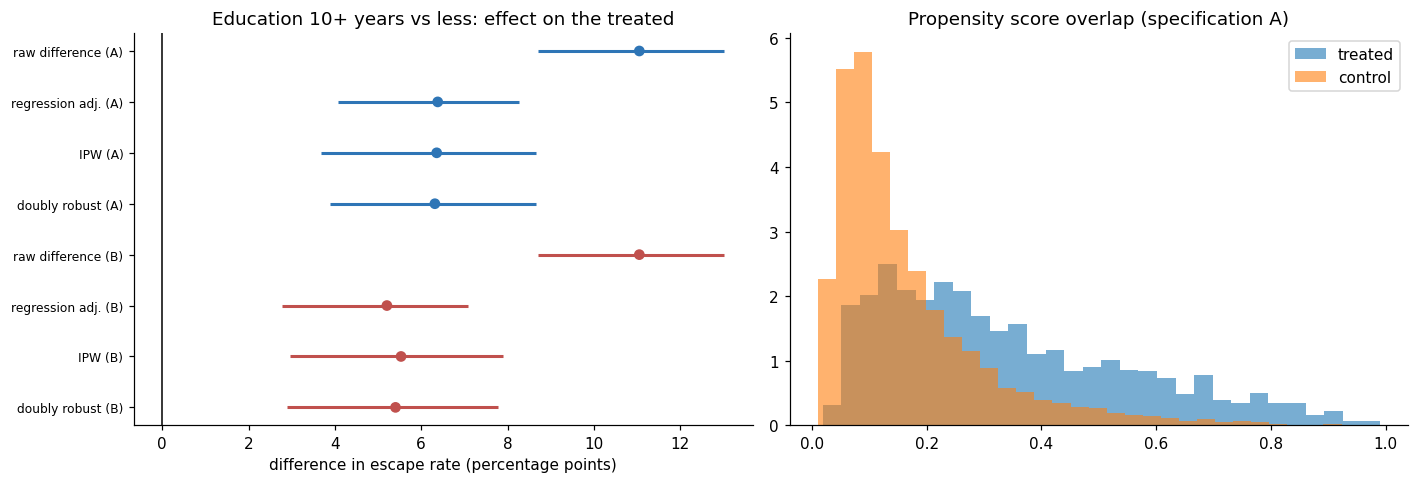

In [44]:
# Chart: the education effect under each estimator and specification (left) and propensity-score overlap (right).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
labels, centres, lows, highs, colours = [], [], [], [], []
for spec_name, colour in [("A: baseline characteristics", "#2e75b6"), ("B: A + baseline poverty gap", "#c0504d")]:
    for key, label in [("raw", "raw difference"), ("regression", "regression adj."), ("ipw", "IPW"), ("doubly_robust", "doubly robust")]:
        r = education_results[spec_name][key]
        labels.append(f"{label} ({spec_name[0]})")
        centres.append(r["estimate"] * 100)
        lows.append(r["ci_low"] * 100)
        highs.append(r["ci_high"] * 100)
        colours.append(colour)
positions = np.arange(len(labels))[::-1]
axes[0].hlines(positions, lows, highs, color=colours, lw=2)
axes[0].scatter(centres, positions, color=colours, zorder=3)
axes[0].axvline(0, color="k", lw=1)
axes[0].set_yticks(positions)
axes[0].set_yticklabels(labels, fontsize=8)
axes[0].set_xlabel("difference in escape rate (percentage points)")
axes[0].set_title("Education 10+ years vs less: effect on the treated")
spec_a_propensity = education_results["A: baseline characteristics"]["propensity"]
axes[1].hist(spec_a_propensity[treated_flag == 1], bins=30, alpha=.6, label="treated", density=True)
axes[1].hist(spec_a_propensity[treated_flag == 0], bins=30, alpha=.6, label="control", density=True)
axes[1].set_title("Propensity score overlap (specification A)")
axes[1].legend()
save_figure("education_effect.png")
plt.show()

REPORT_NUMBERS["education"] = {
    spec: {key: value for key, value in result.items() if key != "propensity"} for spec, result in education_results.items()}
REPORT_NUMBERS["education"]["n_treated"] = int(treated_flag.sum())
REPORT_NUMBERS["education"]["n_control"] = int((1 - treated_flag).sum())


## 12. Save outputs

In [45]:
# Record the library versions used for this run.
import sys
import sklearn
import xgboost
REPORT_NUMBERS["versions"] = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                              "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "shap": shap.__version__}

# Save all key numbers (used to write the report) as a JSON file.
with open(OUTPUT_DIR / "key_numbers.json", "w") as file:
    json.dump(REPORT_NUMBERS, file, indent=2, default=lambda item: item.item() if hasattr(item, "item") else str(item))

# Save the cross-validation fold of every training household (so the folds can be audited and reused).
fold_of_train_row = np.zeros(len(train_idx), dtype=int)
for fold_number, (_, validation_rows) in enumerate(cv):
    fold_of_train_row[validation_rows] = fold_number
pd.DataFrame({"IDHH": data["IDHH"].to_numpy()[train_idx], "cv_fold": fold_of_train_row}).to_csv(
    OUTPUT_DIR / "cv_folds.csv", index=False)

# Save which households were in train and which in test (so the split can be reproduced and audited).
is_test = np.isin(np.arange(len(data)), test_idx)
split_table = data[["IDHH", "ESCAPED"]].assign(split=np.where(is_test, "test", "train"))
split_table.to_csv(OUTPUT_DIR / "modelling_ids_and_split.csv", index=False)

print("Saved to", OUTPUT_DIR.resolve())
print(sorted(path.name for path in OUTPUT_DIR.iterdir()))
print(sorted(path.name for path in FIGURE_DIR.iterdir()))

Saved to C:\aucml\v3final5\outputs
['attrition_ipw.csv', 'attrition_smd.csv', 'calibration_summary.csv', 'cv_folds.csv', 'cv_summary.csv', 'feature_dictionary.csv', 'feature_selection.csv', 'feature_set_comparison.csv', 'figures', 'key_numbers.json', 'logistic_odds_ratios.csv', 'model_comparison.csv', 'model_full_metrics.csv', 'modelling_ids_and_split.csv', 'overfitting_check.csv', 'repeated_split_auc.csv', 'risk_quintile_lift.csv', 'sensitivity_old_line.csv', 'sensitivity_ration_card.csv', 'sensitivity_survey_weights.csv', 'sensitivity_target_rules.csv', 'shap_by_group.csv', 'shap_top_variables.csv']
['confusion_matrices_all_models.png', 'eda_overview.png', 'education_effect.png', 'feature_selection.png', 'results_overview.png', 'risk_quintile_lift.png', 'shap_dependence.png', 'shap_importance.png', 'shap_summary.png', 'shap_waterfall_example.png', 'transition_matrix.png']


In [46]:
# ---- Data behind the presentation charts, and the trained models for the demo app ----
import pickle
import joblib

chart_columns = ["ESCAPED", "Caste/religion", "Area", "Adult education", "Assets tertile", "Head sex"]
chart_dump = {
    "chart_data": chart_data[chart_columns].copy(),
    "y_test": y_test, "test_probs": test_probs, "thresholds": thresholds,
    "best_model_name": best_model_name, "encoded_names": encoded_names,
    "shap_children": shap_values[:, encoded_names.index("n_children_0_5")],
    "x_children": X_test["n_children_0_5"].to_numpy(),
    "shap_assets": shap_values[:, encoded_names.index("assets_per_capita")],
    "x_assets": X_test["assets_per_capita"].to_numpy(),
}
with open(OUTPUT_DIR / "chart_dump.pkl", "wb") as file:
    pickle.dump(chart_dump, file)

# Typical household (median of numeric inputs, most common category) used by the app for inputs the user does not fill in.
default_household = {name: float(X_train[name].median()) for name in NUMERIC}
default_household.update({name: X_train[name].mode().iloc[0] for name in NOMINAL})
bundle = {"models": {name: best_models[name] for name in best_models}, "thresholds": thresholds,
          "features": FEATURES, "numeric": NUMERIC, "nominal": NOMINAL, "feature_info": feature_info,
          "default_household": default_household, "ensemble_name": ENSEMBLE,
          "test_rows": X_test.reset_index(drop=True).assign(ESCAPED=y_test, P_ESCAPE=test_probs["XGBoost"]),
          "versions": REPORT_NUMBERS["versions"]}
joblib.dump(bundle, OUTPUT_DIR / "model_bundle.joblib")
print("Saved chart data and model bundle.")


Saved chart data and model bundle.


## Limitations
- **Only two survey points:** 2004-05 and 2011-12, seven years apart. Households move in and out of poverty between the surveys. Escaping is partly a *noisy crossing of a line*: about one in five of the poor households were within 10% of the line, and the chance of being poor in 2011-12 is about the same just below the 2004-05 line (20%) as just above it (21%). Spending was measured with different questionnaires (47 items in IHDS-I, 52 in IHDS-II), which may add measurement noise. This helps to explain why accuracy is modest (ROC-AUC about 0.70 to 0.72) and why adding features barely helps (Section 10a).
- **Poverty line:** both waves now use the Tendulkar line. The poverty flag supplied in the wave-1 file uses an older line and was **not** used (Section 3). Tendulkar poverty lines have been criticised, and a different line would change which households count as poor.
- **Attrition:** about 11% of poor households cannot be followed to a valid wave-2 flag, and they are more often urban and own less land than those we keep (Section 3). Moving out of the village or town ends the follow-up. The re-weighting in Section 10c shows how much this matters.
- **Split households:** the main target follows the continuing household; Section 10b tests the alternatives. A household can change a lot (members leave, the head dies), so "the same household" is not a constant unit.
- **Association, not cause:** SHAP and the education estimates describe patterns. Hidden factors (ability, networks, local shocks) may remain (see the E-value in Section 11). Ration card type is a government poverty-targeting label: it is legitimate 2004-05 information, but it must not be read as a "risk factor".
- **Consumption and income are not used as inputs** so that SHAP shows the main starting conditions. Section 10a shows what changes when they are added.
- **Health information is thin:** the household file has no direct health measures. Health is represented by deaths in the household, the interviewed woman's self-rated health and the count of diagnosed major illnesses. The illness list contains only people with a diagnosis, and we treat everyone not listed as having none (as the questionnaire instructs). In 261 of the 2,474 villages and urban neighbourhoods nobody at all was listed, about four times what chance would give (about 59), so for some of those households a 0 may mean 'not recorded'. Health is only about 1% of the model's SHAP importance, so this cannot change the results much.
- **Survey weights:** the models are trained unweighted; weighted results are reported as a sensitivity check (Section 10e). The sample over-represents some groups, so results describe this sample, not national totals.
- **Single train/test split:** Section 10f shows how much scores move between splits. Differences between models smaller than that spread should not be over-interpreted.
- **Headline model:** XGBoost was chosen because it has the best cross-validated AUC (a rule fixed before looking at the test set). On the test villages XGBoost and the ensemble differ by about 0.003 AUC, which is not significant; both beat Logistic Regression and Random Forest in most comparisons, and Random Forest and Logistic Regression cannot be told apart.
- **Old data:** the surveys describe India in 2004-2012.
